In [1]:
import json
import os
import re
import warnings
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")
pd.set_option("display.max_colwidth", 130, "display.width", 230, "display.max_columns", 40)

In [2]:
# ---- Paths (relative to analysis/tenant-headlines/) ----
DATA_DIR = Path("../../data/headlines")
PREPARED_PATH = DATA_DIR / "prepared" / "headlines_prepared.csv"
ANNOTATIONS_PATH = DATA_DIR / "annotations" / "framing_annotations.csv"
REVIEW_PATH = DATA_DIR / "review" / "human_review.csv"
FINDINGS_PATH = DATA_DIR / "findings" / "findings_robustness.csv"
CODING_CACHE = DATA_DIR / "review" / "machine_assisted_coding.csv"       # Claude-coded pilot / validation / relevance labels (see section 3)

# ---- Sampling and resampling ----
SEED = 42
N_BOOT = 1000                    # family-cluster bootstrap replicates
N_BOOT_SMALL = 400               # for the robustness grid and subgroup tables
CI = 0.95
PRIMARY_RELEVANCE = ["residential", "unclear"]      # primary sample; commercial and mixed-cue headlines are excluded
PILOT_ALLOCATION = {"tenant": 14, "landlord": 12, "both": 14}   # 40 distinct families
VALIDATION_PER_TYPE = 40                             # held-out random sample: 40 per mention type = 120 families

# ---- Interpretation thresholds ----
MIN_POS_FOR_ESTIMATE = 10        # fewer reference positives (or rule positives) than this = accuracy too uncertain to certify a field
MIN_PRECISION, MIN_RECALL = 0.70, 0.50    # a field needs both (with enough positives) to support corpus-level numerical claims
MIN_CELL = 30                    # a subgroup rate is displayed only with at least this many denominator observations
TOP_OUTLETS = 3                  # leave-out-the-largest-outlets robustness
EXAMPLES_PER_SECTION = 8

# ---- Display ----
COLORS = {"tenant": "#2a78d6", "landlord": "#eb6834"}
INK, MUTED, GRID, NEUTRAL = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
})

# 04 · Representational asymmetries in tenant and landlord headlines

**Purpose.** Notebooks 01–03 asked whether tenants are shown as harmed and passive while landlords act. The answer was mixed. This notebook asks a narrower and more useful question: **in what specific ways, if any, do headlines in this corpus represent tenants less favourably than landlords, and how large and how consistent is each way?** It is not a verdict on "the media". A pattern that disadvantages tenants can sit alongside sympathetic reporting, and reporting that tenants suffer is not by itself unfavourable treatment. Each mechanism is therefore shown with supporting evidence, contradictory evidence, alternative explanations and uncertainty, and a null result closes that line of inquiry.

**Four connected questions** (no further subgroups are opened):
1. *Whose interests and claims are made legitimate?* (rights and security vs investment and income; how interventions are framed; explicit rationales)
2. *How are credibility, blame and deservingness assigned?* (who is judged, in whose voice; how claims are reported; how non-payment is characterised)
3. *How are harms explained and responsibility made visible?* (named decision-makers, stated causes, institutional or market context)
4. *What kind of agency and authority do tenants receive?* (coping, testimony, collective action, demands, expertise, success; assertion versus obstruction)

**Evidence is headline-level.** Nothing here shows what journalists intended, what articles say, or how audiences respond. The data are indexed English-language Canadian headlines retrieved through the words tenant/renter/landlord, with uneven indexing; headline counts are never compared with population shares.

## 1. Where the earlier notebooks left us

The recap below is read from the saved findings table and the data, not typed in.

In [3]:
prepared = pd.read_csv(PREPARED_PATH)
annotations = pd.read_csv(ANNOTATIONS_PATH)
PCOLS = ["id", "title", "url", "publish_date", "year", "media_name", "mention_group", "relevance", "family_id_exact", "family_id_near", "is_rep_exact", "is_rep_near"]
obs_all = annotations.merge(prepared[PCOLS], on="id", how="left", validate="many_to_one")
main_broad = obs_all[obs_all["is_rep_near"]]
nb = pd.DataFrame({"existing check": ["publication rows in the prepared file", "distinct near-duplicate story families with a tenant/landlord mention", "tenant observations (distinct stories)",
                                       "landlord observations (distinct stories)", "families naming both groups"],
                   "this run": [len(prepared), main_broad["family_id_near"].nunique(), int((main_broad["group"] == "tenant").sum()), int((main_broad["group"] == "landlord").sum()),
                                main_broad[main_broad["mention_group"] == "both"]["family_id_near"].nunique()]})
display(nb)
if FINDINGS_PATH.exists():
    f = pd.read_csv(FINDINGS_PATH)
    m = f[(f["spec"] == "main") & (f["analysis"] == "unadjusted")].set_index("outcome")
    show = m[["rate_tenant", "rate_landlord", "diff_pp", "lo_pp", "hi_pp"]].copy()
    show[["rate_tenant", "rate_landlord"]] = (100 * show[["rate_tenant", "rate_landlord"]]).round(1)
    print("Notebook 03 main comparison (rule-based, unvalidated), tenant vs landlord % and tenant − landlord pp:")
    display(show.round(1).rename(columns={"rate_tenant": "tenant %", "rate_landlord": "landlord %"}))

,existing check,this run
0,publication rows in the prepared file,7726
1,distinct near-duplicate story families with a tenant/landlord mention,5939
2,tenant observations (distinct stories),4411
3,landlord observations (distinct stories),2349
4,families naming both groups,821


Notebook 03 main comparison (rule-based, unvalidated), tenant vs landlord % and tenant − landlord pp:


,tenant %,landlord %,diff_pp,lo_pp,hi_pp
outcome,,,,,
harm_experienced,19.8,6.5,13.3,11.8,14.8
act_initiate,3.1,10.0,-7.0,-8.2,-5.6
act_resist,3.8,3.1,0.8,-0.1,1.7
assist_received,7.7,1.6,6.1,5.1,7.1
voice_any,10.5,11.1,-0.6,-2.2,0.9
discussed_by_others,19.4,19.1,0.3,-1.5,2.2
const_org,3.3,1.7,1.6,0.9,2.3
ind_individual,23.4,51.6,-28.2,-30.4,-25.8
wrongdoing,2.6,10.0,-7.4,-8.7,-6.1


**Why those results complicate the original hypothesis.** The differences that *support* it (tenants more often harmed, landlords more often initiating) describe who does what in the underlying event: landlords control housing and tenants live with the consequences, so a headline that reports an eviction will usually show a landlord acting and a tenant affected. That is the event, not necessarily editorial disadvantage. "Initiate" versus "resist" is also a coding split, and resisting, suing and organising are agency. The results that *cut against* it are as large: tenants have more attached organisations and advocates, voice is about equal, and landlords more often appear with wrongdoing or sanctions. Notebook 03's headline individual-case gap is largely a singular/plural wording artifact. None of this tests the mechanisms in the literature below, which concern *how* interests, blame, explanation and agency are represented. That is the subject of this notebook.

## 2. Literature anchors and what they motivate

These sources motivate the questions; they are **not evidence about this corpus**. I consulted **abstract-level text only**, surfaced through web-search listings (the publisher pages themselves returned HTTP 403, so the full texts of Kerrigan, van Ommen and Woodhall-Melnik et al. were not read); the Teen Vogue article could not be retrieved at all, so its description below rests on the brief rather than on the article.

| Source | Context and method | Relevant idea | Proposed headline observation (this notebook) | What headlines cannot establish |
|---|---|---|---|---|
| Kerrigan (2022), *City* 26(4), 587–609 · [doi](https://doi.org/10.1080/13604813.2022.2067719) · *abstract only* | Ontario's 2017–18 rent-control expansion and retrenchment; policy documents and news coverage; feminist theory of hegemonic masculinity | Landlords portrayed as "rational", tenants as "vulnerable", needing paternalistic protection rather than as potentially powerful collective actors | Q1: rights/security vs property/investment claims; how interventions are framed. Q4: coping, testimony and demands vs collective organising, expertise and success | Gendered meanings; Ontario policy politics; anything outside headline wording |
| van Ommen (online 2024; *Housing Studies* 41(1), 2026, 99–124) · [doi](https://doi.org/10.1080/02673037.2024.2439445) · *abstract only* | Close rhetorical analysis of one New Zealand landlord spokesperson's piece plus related items; not a prevalence survey | Tenant-related concerns are framed and countered; commonly used tactics shift responsibility and cost and oppose regulation | Q1: protections framed through burden/threat, and whether those are the headline's own voice or attributed; necessity ("must", "forced to") and who invokes it | Whether those tactics are common in Canada; article-level argument structure |
| Woodhall-Melnik, LeBlanc Haley & Reiser (online 2025; *Housing Studies* 41(1), 2026, 199–233) · [doi](https://doi.org/10.1080/02673037.2024.2446716) · *abstract only* | Media analysis of articles from five prominent Canadian print sources on renoviction | Coverage records common justifications, tenant vulnerabilities, consequences and tenants' attempts to halt renovictions | Q3: whether headlines name an actor, give a cause, justification or context. Q1: stated rationale. Q4: resistance and success | Detailed findings of the paper (not verified from full text); article-level justification content |
| Bosnic (2021), *Teen Vogue*, "How the Real Estate Lobby Exploits Small Landlords" · [link](https://www.teenvogue.com/story/small-landlords-covid-19) · *not retrievable by me* | Reported commentary critiquing sympathetic small-landlord narratives used against tenant protections | Personal-hardship narratives can carry policy-burden arguments | Q1: do hardship/humanising details travel with burden framing of protections? (hypothesis, not an established corpus pattern) | Prevalence; lobbying intent; whether any headline is part of a campaign |

The corpus is not a test of these papers. Where our measures echo a paper's idea, they are our own operationalisation of it.

## 3. Coding scheme, frozen before any comparison

Twelve core fields cover the four questions; **context tags** (event type, incident, pandemic, digest-style headline, humanising detail, financial hardship) are descriptive. Fields are coded per *headline × group observation* (a headline naming both groups gets one for each), except two coded per headline (**intervention frame** with a target group, and **non-payment motive**). Every field is yes/no or a short list of values and has an explicit denominator, an evidence span (the exact words) and an "absent or not assessable" state.

| # | Field | Question | Definition (what the wording must establish) | Denominator |
|---|---|---|---|---|
| 1 | `rights_claim` | Q1 | Group's rights, protections or security of home are the subject ("tenants' rights", "protect renters", "landlord's legal right") | all observations |
| 2 | `property_interest` | Q1 | Landlord's income, costs, investment, property control or rent owed is the subject (defined for landlords; tenants' finances are coded as hardship, not property) | landlord observations |
| 3 | `intervention_frame` | Q1 | A policy/programme/rule is framed as **protective**, **assistance**, **burden_threat**, **accountability** (enforcement against misconduct) or **neutral**; the target group is recorded | headlines with an intervention |
| 4 | `rationale` | Q1 | An explicit reason accompanies the group's action, demand or stance ("to pay for repairs", "over delays") | observations with an action, demand or reported stance |
| 5 | `necessity` | Q1 | Constraint language about the group ("forced to", "must", "no choice") | all observations |
| 6 | `moral_blame` | Q2 | Misconduct or a moral judgment of the group: **own** (asserted in the headline's voice, including findings such as "fined"), **attributed** (allegation, charge, quotation, or a named source), **rejected** (denied or negated) | all observations |
| 7 | `claim_treatment` | Q2 | How the group's reported speech is worded: **plain** (says, explains), **hedged** (claims, alleges, insists), **factive** (reveals, proves). This describes wording, **not** credibility | observations with reported speech |
| 8 | `nonpayment_motive` | Q2 | Characterisation of non-payment: inability, refusal/exploitation, collective withholding, unspecified | headlines mentioning non-payment |
| 9 | `actor_named` | Q3 | A decision-maker or responsible actor is named in the harm headline. Incidents (fire, flood, crime) are excluded from the denominator | tenant-harm headlines about eviction, rent increases or housing conditions |
| 10 | `explanation` | Q3 | Explicit **reason**, **policy** (law, rule, institution), **market** (sale, redevelopment, profit, cost) or **conditions** (crisis, shortage, pandemic) context, or none | same denominator as 9 |
| 11 | `agency_type` | Q4 | Any of: **coping**, **testimony** (about own experience), **collective_org** (organisation or collective action), **demand_claim** (legal, policy or repair demand), **diagnosis_solution**, **expertise** (advocate/lawyer/expert speaking), **success** (a win or effective change) | all observations |
| 12 | `action_character` | Q4 | **rights_assertion** (explicit goal or grievance), **obstruction** (refusal, blockade, destruction, disorder) or unclear | observations with resistance, a demand, organising or an obstructive act |

Exclusions common to all fields: a word is not a label until the wording establishes it (a quotation, a negation or an allegation is a different state from an assertion); landlord responsibility is never imputed from outside knowledge; a missing actor is not coded as bias (headlines are short). There is **no composite "anti-tenant bias score"**.

**Method and provenance.** (a) Candidate retrieval uses transparent regular expressions plus the Notebook 02 annotations. (b) A fixed, balanced **pilot of 40 families** was read and coded by me (Claude) with an evidence span and a rationale for every label; the rules were refined **once** on that pilot and then frozen. (c) A **held-out random sample of 120 families** (40 per mention type, disjoint from the pilot) was coded *before* seeing rule outputs, plus a separate **difficult set** for failure analysis and a **40-headline relevance check**. All labels live in `data/headlines/review/machine_assisted_coding.csv` (schema in section 5). **This is machine-assisted coding, not human validation**: it can show where the rules fail, but I do not certify it as ground truth, and the 120-row human-review file from notebook 02 is checked below in case labels have since been added.

In [4]:
import re, numpy as np, pandas as pd
from functools import lru_cache
G = {"tenant": r"(?:tenants?|renters?)", "landlord": r"(?:landlords?)"}
W = r"(?:[\w'’$.,%-]+\W+)"          # one word + separator
@lru_cache(maxsize=None)
def near(g, cue, k=4):
    """cue within k words of the group word, either order"""
    return re.compile(rf"(?:{cue})\W+{W}{{0,{k}}}?{G[g]}\b|\b{G[g]}\W+{W}{{0,{k}}}?(?:{cue})", re.I)

RIGHTS = r"rights?\b|protections?|protect\w*|security of tenure|safeguard\w*|right to|first"
PROP = r"costs?\b|losses|lose[sd]?|income|profits?|invest\w*|mortgage|property tax\w*|rental income|bottom line|out of pocket|owed|owes?\b|unpaid|arrears|selling|sells?\b|sold|sale|property rights|bidding war|capital repairs|vacancy|buy\w*|purchase\w*|market value|repair costs|\$\s?[\d,.]+\s?[kKmM]?\s+(?:in )?rent|damage[sd]?|wrecked|trashed|fees?\b|taxes"
INTERVENTION = re.compile(r"\b(?:ban\w*|cap\b|freeze\w*|bill\b|law\b|laws\b|rules?\b|program\w*|relief|subsid\w+|plan\b|polic(?:y|ies)|bylaw\w*|licen[sc]\w+|registry|moratorium|tax\w*|legislation|regulat\w+|crack\w* down|reform\w*|changes? to|rent control|pilot|funding|grants?|incentives?|legal changes|guideline|amend\w+|enforce\w*|inspect\w*|rental laws)\b", re.I)
FR_BURDEN = re.compile(r"burden\w*|\bcosts?\b|hurt\w*|\bhits?\b|squeez\w+|threat\w*|drive[sn]? out|exodus|red tape|unfair|disincentive|pull\w* out|selling|worr(?:y|ies|ied)|\bfewer rentals|chill\w*|harm\w*|backfire|unintended|punish\w*|penali[sz]\w*", re.I)
FR_ACCOUNT = re.compile(r"crack\w* down|enforce\w*|\bfine[ds]?\b|licen[sc]\w+|registry|inspect\w*|accountab\w+|oversight|bad landlords|penalt\w+", re.I)
FR_PROTECT = re.compile(r"protect\w*|rights?\b|freeze\w*|\bcap\b|\bban\w*|moratorium|security|safeguard\w*|prevent\w*|\bstop\w*|reform\w*|tenants first|rent control|strengthen\w*", re.I)
FR_ASSIST = re.compile(r"relief|subsid\w+|\baid\b|\bhelp\w*|support\w*|grants?|funding|benefits?|assist\w*|rebates?|supplement|affordable|pilot|incentives?", re.I)
RATIONALE = re.compile(r"\b(?:because|due to|citing|in order to|since|given|ahead of|in response to|so that|to (?:pay|cover|renovate|make|fund|recoup|avoid|prevent|stop|keep|protect|ensure|address|fix|repair|recover|deal|comply|crack|reduce|raise|boost)|over (?!the\b)\w+|after (?!the\b)\w+|amid|as (?:he|she|they|it|rents|costs|the|more|prices|interest)|if (?:they|he|she|it|you)|unless|for (?:renovations?|repairs?|the sale|sale|demolition|personal use|own use)|to protest)\b", re.I)
NECESSITY = re.compile(r"\b(?:forced to|force[sd]? (?:\w+ )?to|have to|had to|has to|must\b|no choice|no option|need(?:s|ed)? to|compelled|obliged|left with no|can'?t afford to|cannot afford to|no other|nowhere to)\b", re.I)
HEDGE = r"claims?|claimed|claiming|alleges?|alleged|allegedly|insists?|insisted|maintains?|so-called|supposed(?:ly)?|purported(?:ly)?|denies|deny"
FACTIVE = r"reveals?|revealed|proves?|exposes?|exposed|shows?\b|confirms?|admits?|admitted|discloses?"
PLAIN = r"says?|said|tells?|told(?! to)|explains?|notes?|adds?|describes?|recalls?|warns?|asks?(?! to)|urges?(?! to)|pleads?|speaks?|laments?|complains?|reacts?|responds?|announces?|states?|comments?|testif\w+|shares?|vows?|pledges?|writes?|pens?"
NONPAY = re.compile(r"arrears|unpaid rent|\bowes?\b|\bowed\b|back rent|behind on rent|non-?payment|stopped paying|refus\w+ to pay|skip\w*(?: out)? on rent|failed to pay|can'?t pay|unable to pay|struggl\w+ to pay|rent strike|withhold\w* rent|won'?t pay|not paying|doesn'?t pay|didn'?t pay|owing", re.I)
NP_INABILITY = re.compile(r"can'?t pay|unable to pay|struggl\w+ to pay|lost (?:\w+ )?(?:job|income)|unemploy\w+|laid off|hardship|can'?t afford|cannot afford|couldn'?t pay|out of work", re.I)
NP_REFUSAL = re.compile(r"refus\w+ to pay|stopped paying|skip\w*|deadbeat|dodg\w+|failed to pay|won'?t pay|no intention|not paying|walk\w* away|scam\w*|fraud\w*|didn'?t pay|doesn'?t pay", re.I)
NP_COLLECTIVE = re.compile(r"rent strike|withhold\w* rent|strike", re.I)
ACTOR = re.compile(r"\b(?:landlords?|owners?|developers?|compan(?:y|ies)|firms?|management|reits?|investors?|corporation|city|municipal\w*|province|provincial|government|board|court|bank|property managers?|building managers?|superintendent|sheriff|housing (?:authority|corporation)|ltb|rtb|council|ford|hospital|university|church)\b", re.I)
EVENT_EVICT = re.compile(r"evict\w*|renovict\w*|demovict\w*|notice to (?:vacate|end)|kick\w* out|lock\w* out|forced out|forced to (?:leave|move|vacate)|displac\w*|turfed|ousted|move[- ]out order|\bvacate\b", re.I)
EVENT_RENT = re.compile(r"rent (?:increase|hike|rise|spike|surge|jump)\w*|(?:increase|hike|raise|raised|jack\w*|boost)\w* (?:\w+ )?rents?|rents? (?:soar|climb|jump|rise|go up)\w*|above[- ]guideline|\bagi\b|rents? (?:are )?(?:up|higher)", re.I)
EVENT_COND = re.compile(r"mou?ld|bed ?bugs?|infest\w*|pests?|cockroach\w*|repairs?|disrepair|\bheat(?:ing)?\b|no heat|air condition\w*|\ba/?c\b|unsafe|uninhabitable|elevator|leak\w*|asbestos|without (?:water|heat|power|hot water)|hot water|conditions?|maintenance|\bdump\b|squalor|rodents?|mice\b", re.I)
INCIDENT = re.compile(r"\bfire\b|\bblaze\b|flood\w*|collapse\w*|explosion|storm|\bshot\b|shoot\w*|stab\w*|murder\w*|kill\w*|\bpolice\b|\bopp\b|arrest\w*|\bcrime\b|\bassault\w*|\bdead\b|\bdeath\b|\bdies\b|\barson\b|\brobb\w*|\bhomicide\b|carbon monoxide|gas leak|evacuat\w*|\binjur\w*", re.I)
EX_REASON = re.compile(r"\b(?:because|due to|citing|since|after (?!the\b)\w+|following|over (?!the\b)\w+|amid|as (?:he|she|they|it|rents|costs|the|more|prices|interest)|to (?:pay|cover|renovate|make|fund|recoup|fix|repair|avoid|prevent|stop|ensure|comply|reduce)|for (?:renovations?|repairs?|the sale|sale|demolition|personal use|own use)|if (?:they|he|she|it|you)|unless|so that)\b", re.I)
EX_POLICY = re.compile(r"\b(?:laws?|legislation|bills?|acts?|bans?|banned|moratorium|rent control|rent cap|cap\b|guideline\w*|board|\bltb\b|\brtb\b|tribunal|province|provincial|government|polic(?:y|ies)|regulat\w+|bylaws?|rules?|legal\w*|ruling|court|order|notice|ford|legali[sz]\w+)\b", re.I)
EX_MARKET = re.compile(r"\b(?:profit\w*|investors?|reits?|developers?|redevelop\w*|demoli\w*|renovat\w*|sale|sell\w*|sold|market|interest rates?|inflation|property tax\w*|capital repairs|costs?|condos?|flipping|speculat\w+|financiali[sz]\w+|make way|rezon\w*|new owner|bought)\b", re.I)
EX_COND = re.compile(r"\b(?:housing crisis|shortage|vacancy|affordab\w+ crisis|crisis|tight|supply|scarcity|pandemic|covid\S*|coronavirus|economy|job losses|homeless\w*|cost of living|inflation)\b", re.I)
COPING = re.compile(r"\b(?:cop(?:e|es|ing)|make do|make ends meet|get by|getting by|living in (?:a )?(?:car|tent|van|rv|truck)|couch.?surf\w*|sleep\w* in|scrambl\w+|resort\w+ to|adapt\w*|find\w* (?:a )?(?:way|new)|downsiz\w+|doubl\w+ up|taking in roommates|skip\w+ meals)\b", re.I)
DIAG = re.compile(r"\b(?:calls? for|urg\w+|propos\w+|recommend\w*|solutions?|need(?:s|ed)?\b|should|must\b|plan\b|will (?:hurt|help|raise|drive|push|lead|force|make|cause|cut|worsen|harm)|could (?:hurt|force|drive|push|lead|cause|worsen)|warns?|says? .{0,40}(?:is|are|will|would|could) )", re.I)
EXPERT = r"advocates?|lawyers?|experts?|economists?|analysts?|researchers?|paralegals?|spokes\w+|legal clinic|legal aid|organizers?|professors?|activists?"
SUCCESS = re.compile(r"\b(?:wins?|won\b|victory|victorious|secures?|secured|succe\w+|halts?|halted|blocks?|blocked|defeats?|defeated|overturns?|overturned|reverses?|reversed|scraps?|scrapped|gets? (?:\w+ )?(?:back|refund|compensation|rent freeze)|stays? (?:in|put)|allowed to stay|keep (?:their|his|her) homes?|forces? (?:\w+ )?(?:to|city|landlord|province))\b", re.I)
OBSTRUCT = re.compile(r"refus\w+ to (?:leave|move|pay|vacate|go)|blockad\w+|barricad\w+|\bblock\w*|squat\w*|occup\w+|stand-?off|disrupt\w*|illegal\w*|\briot\w*|clash\w*|trash\w*|threat\w*|violent|assault\w*|damage[sd]?|burn\w*|obstruct\w*|nuisance|disorder|noisy|\bparty\b|parties|refuses?|won'?t leave|trespass\w*|stolen|steal|break-?in|wreck\w*", re.I)
OBSTRUCT_STRICT = re.compile(r"refus\w+ to (?:leave|move|pay|vacate|go)|blockad\w+|barricad\w+|squat\w*|stand-?off|threaten\w*|trespass\w*|won'?t leave|obstruct\w*", re.I)
ASSERT = re.compile(r"fight\w*|protest\w*|rall(?:y|ies|ied)|demand\w*|push\w* (?:for|back)|petition\w*|organi[sz]\w*|march\w*|strike|oppos\w+|stand\w* up|call\w* (?:for|on)|campaign\w*|urg\w+|\bagainst\b|sue[sd]?|suing|appeal\w*|complain\w*|lobby\w*|speak\w* out|unit\w*|join\w* forces|opposing|resist\w*|challenge[sd]?|take[sn]?.{0,12}to court|dispute[sd]?", re.I)
ORGW = re.compile(r"union|association|group|coalition|organi[sz]\w+|rall(?:y|ies|ied)|protest\w*|strike|petition|federation|alliance|campaign\w*|march\w*|join\w* forces|committee", re.I)
LEGAL_DEMAND = re.compile(r"sue[sd]?|suing|lawsuit|appeal\w*|files?\b|filed|complaint|petition\w*|take[sn]?.{0,12}to court|demand\w*|push\w* for|call\w* for|call\w* on|urg\w+|ask\w*|plea|pleads?|seek\w*|lobby\w*|want\w*|fight\w*", re.I)

def grp_hits(title, g, rx, k=4):
    return bool(near(g, rx.pattern if hasattr(rx, "pattern") else rx, k).search(title))

QUOTED = re.compile(r"[\"“].+?[\"”]|‘.+?’")
def speech_cls(title, g):
    t = QUOTED.sub(" ", title)                      # words inside quotation marks are not the headline's own attribution
    for lab, pat in (("hedged", HEDGE), ("factive", FACTIVE), ("plain", PLAIN)):
        if re.search(rf"\b{G[g]}\b\W+(?:{W}{{0,2}}?)(?:{pat})\b|(?:,|:)\s*(?:{pat})\s+(?:the |a |one )?{G[g]}\W*$", t, re.I):
            return lab
    return ""

def rule_rows(r):
    """One row per observation (headline x group) -> dict of rule predictions."""
    t, g = r["title"], r["group"]
    o = {}
    o["rights_claim"] = bool(near(g, RIGHTS).search(t))
    o["property_interest"] = bool(g == "landlord" and re.search(PROP, t, re.I))
    act = bool(r["act_initiate"] or r["act_resist"])
    act = bool(act or r["voice_demands"] or r["voice_speaks"])
    o["rationale_den"] = act
    o["rationale"] = bool(act and RATIONALE.search(t))
    o["necessity"] = bool(near(g, NECESSITY.pattern, 6).search(t))
    # blame / derogation status
    cue = bool(r["wrongdoing"] or r["derogatory_any"] or r["responsibility"])
    if cue:
        ev = str(r["evidence"])
        if r["ctx_negated"] and "NEG:" in ev: st = "rejected"
        elif r["ctx_alleged"] or r["ctx_quoted"] or re.search(r"wrongdoing:(?:charge|accuse|sue|arrest|allege|complaint|investigat|probe)|\bsays?\b|\bsaid\b|police|alleg|accus", ev + " " + t, re.I): st = "attributed"
        else: st = "own"
    else: st = ""
    o["moral_blame"] = st
    o["claim_treatment"] = speech_cls(t, g)
    # event type for Q3
    ev_e, ev_r, ev_c = bool(EVENT_EVICT.search(t)), bool(EVENT_RENT.search(t)), bool(EVENT_COND.search(t))
    inc = bool(INCIDENT.search(t))
    harm = bool(r["harm_experienced"])
    o["q3_den"] = bool(g == "tenant" and (ev_e or ev_r or ev_c) and not inc)
    o["incident"] = inc
    others = ACTOR.sub(lambda m: m.group(0) if m.group(0).lower() not in ("landlord","landlords") else "", t)
    named = bool(ACTOR.search(re.sub(r"\b(?:tenants?|renters?)\b", "", t, flags=re.I)))
    if r["mention_group"] == "both": named = True
    o["actor_named"] = bool(o["q3_den"] and named)
    for k, rx in (("reason", EX_REASON), ("policy", EX_POLICY), ("market", EX_MARKET), ("conditions", EX_COND)):
        o["ex_" + k] = bool(o["q3_den"] and rx.search(t))
    # agency types
    sp = bool(r["voice_speaks"]); dem = bool(r["voice_demands"]); via = bool(r["voice_via_org"])
    o["ag_coping"] = bool(COPING.search(t) and near(g, COPING.pattern, 8).search(t))
    first_person = bool(re.search(r"[\"“‘'].*\b(?:I|we|my|our|I'm|I’ve|we’re|me)\b.*[\"”’']", t))
    exp_cue = bool(r["harm_experienced"] or r["topic_conditions"] or r["topic_eviction"] or r["topic_dispute"])
    own_verb = bool(re.search(r"\b(?:says?|said|tells?|told|describes?|recalls?|recounts?|shares?|explains?)\b", t, re.I)) and not re.search(r"\bwarns?\b", t, re.I)
    o["ag_testimony"] = bool(sp and ((own_verb and exp_cue and r["ind_individual"]) or first_person))
    o["ag_collective_org"] = bool(r["const_org"] or (r["topic_organizing"] and ORGW.search(t) and re.search(rf"\b{G[g]}", t, re.I)))
    o["ag_demand_claim"] = bool(dem or (r["act_resist"] and LEGAL_DEMAND.search(t)))
    o["ag_diagnosis_solution"] = bool((sp or dem or via) and DIAG.search(t))
    o["ag_expertise"] = bool(near(g, EXPERT, 3).search(t) or (via and re.search(EXPERT, t, re.I)))
    o["ag_success"] = bool(near(g, SUCCESS.pattern, 6).search(t) or (g and re.search(rf"{SUCCESS.pattern}", t, re.I) and r["act_resist"] and re.search(r"\bwin|won|victory|succe", t, re.I)))
    o["action_den"] = bool(r["act_resist"] or r["voice_demands"] or (r["topic_organizing"] and re.search(ORGW, t)) or (r["gram_role"] == "active_subject" and OBSTRUCT_STRICT.search(t)))
    if o["action_den"]:
        a, ob = bool(ASSERT.search(t)), bool(OBSTRUCT.search(t))
        o["action_character"] = "rights_assertion" if a else ("obstruction" if ob else "unclear")
    else: o["action_character"] = ""
    return o

def headline_rules(h):
    """Headline-level: intervention frame + target; nonpayment motive."""
    t = h["title"]; out = {"intervention": "", "intervention_target": "", "nonpay_motive": "", "nonpay_payer": ""}
    if INTERVENTION.search(t) or h["topic_regulation"]:
        lack = re.search(r"(?:lack of|without|\bno\b|cuts? to|end of|absence of) (?:\w+ ){0,2}(?:relief|aid|support|subsid\w+|funding|help)", t, re.I)
        fr = "assistance" if lack else "burden_threat" if FR_BURDEN.search(t) else "accountability" if FR_ACCOUNT.search(t) else "protective" if FR_PROTECT.search(t) else "assistance" if FR_ASSIST.search(t) else "neutral"
        out["intervention"] = fr
        # target = group nearest to the intervention term
        m = INTERVENTION.search(t) or re.search(r".", t)
        pos = {gname: [x.start() for x in re.finditer(G[gname], t, re.I)] for gname in G}
        best = min(((abs(p - m.start()), gname) for gname, ps in pos.items() for p in ps), default=(0, ""))
        out["intervention_target"] = best[1]
    if NONPAY.search(t):
        out["nonpay_motive"] = "inability" if NP_INABILITY.search(t) else "collective" if NP_COLLECTIVE.search(t) else "refusal" if NP_REFUSAL.search(t) else "unspecified"
        out["nonpay_payer"] = "tenant" if re.search(G["tenant"], t, re.I) else ("landlord" if re.search(G["landlord"], t, re.I) else "")
    return out


# ---- descriptive context tags (not core fields) ----
HUMAN = r"\d{1,3}-year-old|single (?:mother|father|parent|mom|dad)|seniors?|elderly|retire\w+|widow\w*|veterans?|disabled|disabilit\w+|students?|famil(?:y|ies)|mothers?|fathers?|grandm\w+|pensioners?|newcomers?|refugees?|nurses?|fixed income|low-income|children|kids"
HARDSHIP_FIN = r"can'?t afford|cannot afford|out of pocket|owed|losses|bankrupt\w*|struggl\w+|fixed income|living on|going without|behind on|debt|broke|priced out|out \$[\d,.]+"
DIGEST = re.compile(r"\bToday:|\s\+\s|\bLETTERS?\b|Letter of the Day|ASK AMY|^Opinion\b|^Q ?:|\bBriefs?\b|Five Things|\bNewsletter\b|\bPodcast\b|^Video:|letters to the editor|Best reads", re.I)
PANDEMIC = re.compile(r"covid\S*|coronavirus|pandemic|lockdown|moratorium|\bcecra\b|rent relief", re.I)
def context_tags(r):
    t, g = r["title"], r["group"]
    return {"humanizing": bool(near(g, HUMAN, 4).search(t)), "fin_hardship": bool(near(g, HARDSHIP_FIN, 6).search(t)),
            "digest": bool(DIGEST.search(t)), "pandemic": bool(PANDEMIC.search(t)),
            "event_evict": bool(EVENT_EVICT.search(t)), "event_rent": bool(EVENT_RENT.search(t)), "event_cond": bool(EVENT_COND.search(t))}

## 4. Data audit and sample flow

The primary sample keeps **residential and unclear** headlines and drops obvious commercial and mixed-cue ones; strict-residential and the broad sample are robustness checks. One representative per near-duplicate family gives distinct stories; exact-title families and publication copies are sensitivity views.

In [5]:
review = pd.read_csv(REVIEW_PATH, dtype=str, keep_default_na=False)
lab_cols = [c for c in review.columns if c.startswith("h_") and c != "h_notes"]
n_human = int(review[lab_cols].isin(["0", "1"]).sum().sum())
print(f"Human-review file: {len(review)} rows, {n_human} completed label cells" + (" (still blank: nothing in this notebook is human-validated)" if n_human == 0 else " (labels are present; see the note in section 5)"))

# regex rules applied to every observation row (publication copies included)
records = obs_all.to_dict("records")
rule_df = pd.DataFrame([{**rule_rows(r), **context_tags(r)} for r in tqdm(records, desc="applying frozen rules")])
rule_df = rule_df.add_prefix("r_")
OBS = pd.concat([obs_all.reset_index(drop=True), rule_df], axis=1)
head_df = OBS.drop_duplicates("id")[["id", "title", "topic_regulation"]]
head_rules = pd.DataFrame([{"id": r["id"], **headline_rules(r)} for r in tqdm(head_df.to_dict("records"), desc="headline-level rules")])
HEAD = prepared[["id", "title", "url", "publish_date", "year", "media_name", "mention_group", "relevance", "family_id_near", "family_id_exact", "is_rep_near", "is_rep_exact"]].merge(head_rules, on="id")

main = OBS[OBS["is_rep_near"] & OBS["relevance"].isin(PRIMARY_RELEVANCE)].copy()           # primary sample
flow = pd.DataFrame({
    "step": ["publication rows with a tenant/landlord mention", "→ near-duplicate story families", "→ distinct-story observations (broad)", "→ primary sample (residential + unclear)",
             "→ strict residential only"],
    "tenant obs": ["", "", int(((OBS["group"] == "tenant") & OBS["is_rep_near"]).sum()), int((main["group"] == "tenant").sum()),
                   int(((OBS["group"] == "tenant") & OBS["is_rep_near"] & (OBS["relevance"] == "residential")).sum())],
    "landlord obs": ["", "", int(((OBS["group"] == "landlord") & OBS["is_rep_near"]).sum()), int((main["group"] == "landlord").sum()),
                     int(((OBS["group"] == "landlord") & OBS["is_rep_near"] & (OBS["relevance"] == "residential")).sum())],
    "headlines/families": [OBS["id"].nunique(), OBS["family_id_near"].nunique(), main_broad["family_id_near"].nunique(), main["family_id_near"].nunique(),
                           OBS[OBS["is_rep_near"] & (OBS["relevance"] == "residential")]["family_id_near"].nunique()]})
display(flow)
loss = main_broad.groupby(["group", "relevance"]).size().unstack(fill_value=0)
loss["% dropped from primary"] = (100 * loss[[c for c in ["commercial", "mixed_cues"] if c in loss]].sum(axis=1) / loss.sum(axis=1)).round(1)
print("Observations dropped by the relevance filter, by group (relevance tags are automatic):")
display(loss)

Human-review file: 120 rows, 0 completed label cells (still blank: nothing in this notebook is human-validated)


applying frozen rules:   0%|          | 0/8660 [00:00<?, ?it/s]

headline-level rules:   0%|          | 0/7587 [00:00<?, ?it/s]

,step,tenant obs,landlord obs,headlines/families
0,publication rows with a tenant/landlord mention,,,7587
1,→ near-duplicate story families,,,5939
2,→ distinct-story observations (broad),4411,2349,5939
3,→ primary sample (residential + unclear),4260,2149,5611
4,→ strict residential only,3091,1147,3785


Observations dropped by the relevance filter, by group (relevance tags are automatic):


relevance,commercial,mixed_cues,residential,unclear,% dropped from primary
group,,,,,
landlord,91,109,1147,1002,8.5
tenant,100,51,3091,1169,3.4


**Relevance check.** The automatic relevance tags decide who is in the primary sample, so I judged a balanced sample of 20 *unclear* and 20 *mixed-cue* families by hand (cached labels, section 5).

In [6]:
coding = pd.read_csv(CODING_CACHE, dtype=str, keep_default_na=False)
relchk = coding[(coding["phase"] == "relevance_check")].copy()
relchk["tag"] = relchk["evidence"]
relchk["ok"] = relchk["value"].map({"1": "residential rental", "0": "not residential rental", "?": "uncertain"})
display(relchk.groupby(["tag", "ok"]).size().unstack(fill_value=0))
rel_unclear_ok = (relchk[relchk["tag"] == "unclear"]["value"] == "1").mean()
rel_mixed_ok = (relchk[relchk["tag"] == "mixed_cues"]["value"] == "1").mean()
print(f"By my reading, {100 * rel_unclear_ok:.0f}% of sampled 'unclear' headlines are clearly residential-rental and {100 * rel_mixed_ok:.0f}% of 'mixed_cues' ones are; "
      "'unclear' is kept in the primary sample, and 'mixed_cues' (mostly commercial) stays out. Uncertain cases are mostly crime/incident stories that mention a landlord or tenant.")

ok,not residential rental,residential rental,uncertain
tag,,,
mixed_cues,17,3,0
unclear,2,13,5


By my reading, 65% of sampled 'unclear' headlines are clearly residential-rental and 15% of 'mixed_cues' ones are; 'unclear' is kept in the primary sample, and 'mixed_cues' (mostly commercial) stays out. Uncertain cases are mostly crime/incident stories that mention a landlord or tenant.


### Pilot headlines

A few of the 40 pilot families with my coding, to show what a "label" means here (evidence span and rationale are stored for every label).

In [7]:
pil = coding[(coding["phase"] == "pilot") & (coding["field"] != "sampled")]
reg = prepared.set_index("id")[["title", "media_name", "year", "mention_group"]]
show_keys = ["P09", "P15", "P21", "P32", "P33", "P34", "P35", "P39"]
sh = pil[pil["sample_key"].isin(show_keys)].copy()
sh["title"] = sh["id"].map(reg["title"]).str.slice(0, 95)
sh = sh[["sample_key", "title", "group", "field", "value", "evidence", "rationale"]]
sh["evidence"] = sh["evidence"].str.slice(0, 55)
sh["rationale"] = sh["rationale"].str.slice(0, 60)
display(sh.head(24).reset_index(drop=True))

,sample_key,title,group,field,value,evidence,rationale
0,P09,"Tenants have fewer protections than 'animals,' Saskatoon lawyer says",tenant,agency_type,expertise,Saskatoon lawyer says,lawyer speaking for tenants
1,P09,"Tenants have fewer protections than 'animals,' Saskatoon lawyer says",tenant,agency_type,diagnosis_solution,fewer protections than 'animals',diagnoses a policy gap
2,P09,"Tenants have fewer protections than 'animals,' Saskatoon lawyer says",tenant,rights_claim,1,fewer protections,rights/protections are the subject
3,P09,"Tenants have fewer protections than 'animals,' Saskatoon lawyer says",tenant,claim_treatment,plain,says,neutral reporting verb
4,P15,Rent control debate: More N.S. landlords consider selling units as advocate calls for permanent,landlord,property_interest,1,landlords consider selling units,landlord asset decision tied to rent control
5,P15,Rent control debate: More N.S. landlords consider selling units as advocate calls for permanent,landlord,intervention_frame,burden_threat,More N.S. landlords consider selling units as advocate,juxtaposes cap with asserted supply withdrawal
6,P21,They can get away with a lot': Council committee votes to crack down on bad Toronto landlords,landlord,intervention_frame,accountability,crack down on bad Toronto landlords,enforcement against misconduct
7,P21,They can get away with a lot': Council committee votes to crack down on bad Toronto landlords,landlord,moral_blame,own,bad Toronto landlords,headline's own evaluative label
8,P32,"Winnipeg landlord fined $9,000 for evicting College Avenue tenants without notice",landlord,moral_blame,own,"landlord fined $9,000",sanction reported as finding
9,P32,"Winnipeg landlord fined $9,000 for evicting College Avenue tenants without notice",tenant,actor_named,1,landlord fined ... for evicting,landlord named as evictor


## 5. Validation of the frozen rules against the machine-assisted reference

The reference labels are **mine** (Claude), assigned from the headline wording alone before looking at rule output, for a held-out random sample (40 families per mention type, drawn with seeded sampling and disjoint from the pilot). They are **not human labels** and are not certified; they let us see which rules are usable. Metrics are computed on observations, and the random sample is weighted by the inverse sampling fraction of each mention-type stratum (tenant-only, landlord-only, both). The **difficult** set (headlines chosen *because* they stress rare fields) is reported separately and is never used for corpus-level error rates.

Cache schema (`machine_assisted_coding.csv`): `phase` (pilot / validation_random / validation_difficult / relevance_check), `sample_key`, `family_id_near`, `id`, `group` (tenant, landlord or headline), `field`, `value`, `evidence` (exact words), `rationale`, `coder`. A `sampled` row registers every sampled headline so that *absence of a field* is a labelled "no".

In [8]:
def draw_pilot(prim, alloc, seed=SEED, in_context_share=0.7, outlet_cap=3):
    """Balanced, seeded pilot: by mention type, ~70% from relevant contexts, at most 3 per outlet."""
    ctx = ["topic_regulation", "topic_affordability", "topic_eviction", "topic_conditions", "topic_organizing", "topic_dispute"]
    rng = np.random.default_rng(seed)
    hl = prim.drop_duplicates("family_id_near")[["family_id_near", "mention_group", "media_name"] + ctx].copy()
    hl["in_context"] = hl[ctx].any(axis=1)
    chosen = []
    for g, n in alloc.items():
        k_ctx = int(round(n * in_context_share))
        for flag, k in [(True, k_ctx), (False, n - k_ctx)]:
            pool = hl[(hl["mention_group"] == g) & (hl["in_context"] == flag) & ~hl["family_id_near"].isin(chosen)].sample(frac=1, random_state=int(rng.integers(1 << 30)))
            cnt, got = {}, 0
            for r in pool.itertuples():
                if cnt.get(r.media_name, 0) < outlet_cap:
                    chosen.append(r.family_id_near); cnt[r.media_name] = cnt.get(r.media_name, 0) + 1; got += 1
                if got == k:
                    break
    return chosen


def draw_validation(prim, pilot_fams, per_type=VALIDATION_PER_TYPE, seed=SEED + 1):
    rng = np.random.default_rng(seed)
    hl = prim.drop_duplicates("family_id_near")[["family_id_near", "mention_group"]]
    hl = hl[~hl["family_id_near"].isin(pilot_fams)].sort_values("family_id_near")
    out = []
    for g in ["tenant", "landlord", "both"]:
        out += list(hl[hl["mention_group"] == g].sample(per_type, random_state=int(rng.integers(1 << 30)))["family_id_near"])
    return out, hl.groupby("mention_group").size().to_dict()


pilot_fams = draw_pilot(main, PILOT_ALLOCATION)
val_fams, frame_sizes = draw_validation(main, pilot_fams)
cache_val = coding[(coding["phase"] == "validation_random") & (coding["field"] == "sampled")]["family_id_near"].tolist()
cache_pil = coding[(coding["phase"] == "pilot") & (coding["field"] == "sampled")]["family_id_near"].tolist()
print("Seeded draws reproduce the labelled samples:", set(cache_val) == set(val_fams), "(validation),", set(cache_pil) == set(pilot_fams), "(pilot).",
      "Sampling frame (families not in the pilot):", frame_sizes)
WEIGHT = {g: frame_sizes[g] / VALIDATION_PER_TYPE for g in frame_sizes}

Seeded draws reproduce the labelled samples: True (validation), True (pilot). Sampling frame (families not in the pilot): {'both': 784, 'landlord': 1339, 'tenant': 3448}


In [9]:
def reference_sets(phase):
    """Reference (manual) labels as sets of (family, group[, value]) per field, over relevant sampled headlines."""
    c = coding[coding["phase"] == phase]
    sampled = c[c["field"] == "sampled"]
    irrelevant = set(c[(c["field"] == "relevance_ok") & (c["value"] == "0")]["family_id_near"])
    fams = [f for f in sampled["family_id_near"] if f not in irrelevant]
    lab = c[(c["field"] != "sampled") & ~c["family_id_near"].isin(irrelevant) & (c["field"] != "relevance_ok")]
    return fams, lab, irrelevant


BOOL_FIELDS = {"rights_claim": "r_rights_claim", "property_interest": "r_property_interest", "rationale": "r_rationale", "necessity": "r_necessity"}
AGENCY = ["coping", "testimony", "collective_org", "demand_claim", "diagnosis_solution", "expertise", "success"]
EXPL = ["reason", "policy", "market", "conditions"]


def build_eval(phase):
    fams, lab, irrelevant = reference_sets(phase)
    o = OBS[OBS["is_rep_near"] & OBS["family_id_near"].isin(fams) & OBS["relevance"].isin(PRIMARY_RELEVANCE + ["commercial", "mixed_cues"])].copy()
    o["key"] = list(zip(o["family_id_near"], o["group"]))
    h = HEAD[HEAD["is_rep_near"] & HEAD["family_id_near"].isin(fams)].set_index("family_id_near")
    mention = h["mention_group"]
    w_of = (lambda k: WEIGHT.get(mention.get(k[0], "both"), 1.0)) if phase == "validation_random" else (lambda k: 1.0)
    rows = []

    def add(name, scope, man, pred, den_keys=None):
        if den_keys is not None:
            man, pred = {k for k in man if k in den_keys}, {k for k in pred if k in den_keys}
        wt = lambda s: sum(w_of(k) for k in s)
        tp, fp, fn = wt(man & pred), wt(pred - man), wt(man - pred)
        rows.append({"field": name, "scope": scope, "ref_pos": len(man), "rule_pos": len(pred), "TP": len(man & pred), "FP": len(pred - man), "FN": len(man - pred),
                     "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan})

    def man_set(field, value=None, group_in=("tenant", "landlord")):
        s = lab[(lab["field"] == field) & lab["group"].isin(group_in)]
        if value is not None:
            s = s[s["value"] == value]
        return set(zip(s["family_id_near"], s["group"]))

    def pred_set(col, val=True, groups=("tenant", "landlord")):
        s = o[(o[col] == val) & o["group"].isin(groups)]
        return set(s["key"])

    for fld, col in BOOL_FIELDS.items():
        for g in ["tenant", "landlord"]:
            add(fld, g, {k for k in man_set(fld) if k[1] == g}, {k for k in pred_set(col) if k[1] == g})
    for v in ["own", "attributed", "rejected"]:
        for g in ["tenant", "landlord"]:
            add(f"moral_blame={v}", g, {k for k in man_set("moral_blame", v) if k[1] == g}, {k for k in pred_set("r_moral_blame", v) if k[1] == g})
    for v in ["plain", "hedged", "factive"]:
        add(f"claim_treatment={v}", "both groups", man_set("claim_treatment", v), pred_set("r_claim_treatment", v))
    assessed = {(f, "tenant") for f in lab[(lab["field"] == "actor_named")]["family_id_near"]}
    am = lab[(lab["field"] == "actor_named") & (lab["group"] == "tenant") & (lab["value"] == "1")]
    add("actor_named=1", "tenant (assessed headlines)", set(zip(am["family_id_near"], am["group"])), pred_set("r_actor_named", True, ("tenant",)), den_keys=assessed)
    for v in EXPL:
        ev = lab[(lab["field"] == "explanation") & (lab["value"] == v)]
        add(f"explanation={v}", "tenant (assessed headlines)", set(zip(ev["family_id_near"], ev["group"])), pred_set("r_ex_" + v, True, ("tenant",)), den_keys=assessed)
    for v in AGENCY:
        for g in ["tenant", "landlord"]:
            add(f"agency={v}", g, {k for k in man_set("agency_type", v) if k[1] == g}, {k for k in pred_set("r_ag_" + v) if k[1] == g})
    for v in ["rights_assertion", "obstruction"]:
        add(f"action={v}", "both groups", man_set("action_character", v), pred_set("r_action_character", v))
    for v in ["protective", "assistance", "burden_threat", "accountability"]:
        mset = set(lab[(lab["field"] == "intervention_frame") & (lab["value"] == v)]["family_id_near"])
        pset = set(h[h["intervention"] == v].index)
        tp, fp, fn = len(mset & pset), len(pset - mset), len(mset - pset)
        rows.append({"field": f"intervention={v}", "scope": "headline", "ref_pos": len(mset), "rule_pos": len(pset), "TP": tp, "FP": fp, "FN": fn,
                     "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan})
    for v in ["refusal", "inability", "collective", "unspecified"]:
        mset = set(lab[(lab["field"] == "nonpayment_motive") & (lab["value"] == v)]["family_id_near"])
        pset = set(h[h["nonpay_motive"] == v].index)
        tp, fp, fn = len(mset & pset), len(pset - mset), len(mset - pset)
        rows.append({"field": f"nonpayment={v}", "scope": "headline", "ref_pos": len(mset), "rule_pos": len(pset), "TP": tp, "FP": fp, "FN": fn,
                     "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan})
    return pd.DataFrame(rows), len(fams), len(irrelevant)


val_random, n_rand, n_irr = build_eval("validation_random")
val_random["usable"] = (val_random["ref_pos"] >= MIN_POS_FOR_ESTIMATE) & (val_random["rule_pos"] >= MIN_POS_FOR_ESTIMATE) & (val_random["precision"] >= MIN_PRECISION) & (val_random["recall"] >= MIN_RECALL)
val_random["too_few"] = (val_random["ref_pos"] < MIN_POS_FOR_ESTIMATE) | (val_random["rule_pos"] < MIN_POS_FOR_ESTIMATE)
print(f"Random validation sample: {n_rand} relevant families scored ({n_irr} of the 120 were judged not residential-rental and set aside). Weighted precision/recall; "
      f"'too_few' = fewer than {MIN_POS_FOR_ESTIMATE} reference or rule positives, so the accuracy itself is too uncertain to certify.")
display(val_random.round(2).set_index(["field", "scope"]))

Random validation sample: 115 relevant families scored (5 of the 120 were judged not residential-rental and set aside). Weighted precision/recall; 'too_few' = fewer than 10 reference or rule positives, so the accuracy itself is too uncertain to certify.


ref_pos  rule_pos  TP  FP  FN  precision  recall  usable  too_few
field                       scope                                                                                         
rights_claim                tenant                             1         2   1   1   0       0.50    1.00   False     True
                            landlord                           2         1   1   0   1       1.00    0.37   False     True
property_interest           tenant                             0         0   0   0   0        NaN     NaN   False     True
                            landlord                          11         7   2   5   9       0.30    0.21   False     True
rationale                   tenant                             2         1   0   1   2       0.00    0.00   False     True
                            landlord                           4         3   0   3   4       0.00    0.00   False     True
necessity                   tenant                             1         4   1   3   0       0.59    1.00   False     True
                            landlord                           4         5   3   2   1       0.69    0.82   False     True
moral_blame=own             tenant                             3         2   0   2   3       0.00    0.00   False     True
                            landlord                          10         4   4   0   6       1.00    0.42   False     True
moral_blame=attributed      tenant                             5         2   1   1   4       0.81    0.37   False     True
                            landlord                          12         6   5   1   7       0.88    0.50   False     True
moral_blame=rejected        tenant                             0         0   0   0   0        NaN     NaN   False     True
                            landlord                           0         0   0   0   0        NaN     NaN   False     True
claim_treatment=plain       both groups                       14         7   7   0   7       1.00    0.37   False     True
claim_treatment=hedged      both groups                        1         2   0   2   1       0.00    0.00   False     True
claim_treatment=factive     both groups                        0         0   0   0   0        NaN     NaN   False     True
actor_named=1               tenant (assessed headlines)       13         8   8   0   5       1.00    0.62   False     True
explanation=reason          tenant (assessed headlines)        4         1   0   1   4       0.00    0.00   False     True
explanation=policy          tenant (assessed headlines)        4         4   2   2   2       0.27    0.50   False     True
explanation=market          tenant (assessed headlines)        6         1   1   0   5       1.00    0.08   False     True
explanation=conditions      tenant (assessed headlines)        0         1   0   1   0       0.00     NaN   False     True
agency=coping               tenant                             1         0   0   0   1        NaN    0.00   False     True
                            landlord                           0         0   0   0   0        NaN     NaN   False     True
agency=testimony            tenant                             7         0   0   0   7        NaN    0.00   False     True
                            landlord                           2         2   1   1   1       0.50    0.37   False     True
agency=collective_org       tenant                             3         3   2   1   1       0.67    0.31   False     True
                            landlord                           3         6   3   3   0       0.54    1.00   False     True
agency=demand_claim         tenant                             1         3   0   3   1       0.00    0.00   False     True
                            landlord                           2         2   0   2   2       0.00    0.00   False     True
agency=diagnosis_solution   tenant                             1         2   0   2   1       0.00    0.00   False     Tru

In [10]:
val_diff, n_diff, _ = build_eval("validation_difficult")
print(f"Difficult set ({n_diff} headlines chosen to stress rare fields; NOT for corpus error rates): where the rules fail")
display(val_diff[(val_diff["FP"] > 0) | (val_diff["FN"] > 0)].round(2).set_index(["field", "scope"]))

Difficult set (18 headlines chosen to stress rare fields; NOT for corpus error rates): where the rules fail


ref_pos  rule_pos  TP  FP  FN  precision  recall
field                   scope                                                                        
property_interest       landlord                           1         1   0   1   1       0.00    0.00
rationale               tenant                             1         3   1   2   0       0.33    1.00
                        landlord                           1         3   0   3   1       0.00    0.00
necessity               tenant                             1         0   0   0   1        NaN    0.00
moral_blame=attributed  tenant                             1         0   0   0   1        NaN    0.00
                        landlord                           3         1   1   0   2       1.00    0.33
claim_treatment=hedged  both groups                        2         3   1   2   1       0.33    0.50
explanation=reason      tenant (assessed headlines)        1         1   0   1   1       0.00    0.00
agency=testimony        tenant                             1         0   0   0   1        NaN    0.00
agency=collective_org   tenant                             1         0   0   0   1        NaN    0.00
agency=success          tenant                             0         2   0   2   0       0.00     NaN
                        landlord                           0         1   0   1   0       0.00     NaN
action=rights_assertion both groups                        2         1   1   0   1       1.00    0.50
action=obstruction      both groups                        3         4   2   2   1       0.50    0.67
intervention=assistance headline                           0         1   0   1   0       0.00     NaN

**How validation limits the claims below.** A field supports a *numerical corpus-level claim* only if it clears the thresholds on the random sample (enough reference positives, precision ≥ 0.70, recall ≥ 0.50). Fields that fail are narrowed to the cases they handle reliably, reported as **qualitative illustration** only, or excluded. The assignment is generated below and referred to in every section.

In [11]:
def verdict_row(r):
    if r["too_few"]:
        return "too few reference/rule positives to certify"
    return "usable for numerical claims (provisional)" if r["usable"] else "weak: qualitative / narrowed only"


val_random["status"] = val_random.apply(verdict_row, axis=1)
FIELD_STATUS = val_random.groupby("field")["status"].agg(lambda s: "usable for numerical claims (provisional)" if (s == "usable for numerical claims (provisional)").any() and not s.str.startswith("weak").any()
                                                          else ("weak: qualitative / narrowed only" if s.str.startswith("weak").any() else "too few reference/rule positives to certify"))
print(FIELD_STATUS.value_counts().to_string())
display(FIELD_STATUS.rename("status").to_frame())

status
too few reference/rule positives to certify    32


,status
field,
action=obstruction,too few reference/rule positives to certify
action=rights_assertion,too few reference/rule positives to certify
actor_named=1,too few reference/rule positives to certify
agency=collective_org,too few reference/rule positives to certify
agency=coping,too few reference/rule positives to certify
agency=demand_claim,too few reference/rule positives to certify
agency=diagnosis_solution,too few reference/rule positives to certify
agency=expertise,too few reference/rule positives to certify
agency=success,too few reference/rule positives to certify


## 6. Close-reading samples: how the four questions are measured

Validation (section 5) shows that the regular-expression rules are good enough to **retrieve candidates** but not, for most fields, to **label** them: many rules miss positives that a reader catches, and several fields have too few examples to certify at all. So each question is answered from a **seeded, stratified random sample of its candidate headlines that I read and coded in full** (same codebook, wording only, rules not consulted while coding), and the corpus-wide rule flags are used only for retrieval and for the outlet comparison in Q3.

| Question | Candidate set (retrieved by transparent rules, primary sample) | Sample coded |
|---|---|---|
| Q1 | headlines with a policy/programme/rule term or in the regulation or affordability topics | 280 headlines: 100 tenant-only, 100 landlord-only, 80 naming both |
| Q2 | observations with blame/judgment cues, reported speech, or non-payment wording | 300 observations: 150 tenant, 150 landlord |
| Q3 | tenant observations about eviction, rent increases or housing conditions, incidents excluded | 200 headlines: 130 tenant-only, 70 naming both |
| Q4 | observations with resistance, a demand, organising, or any agency cue | 300 observations: 150 tenant, 150 landlord |

Each stratum is weighted by (candidates in the stratum) ÷ (coded in the stratum), and intervals come from a bootstrap that resamples the coded items within strata. **What the rates mean:** *the rate among candidate headlines of that group*, which is the conditional rate where the mechanism can occur. Because retrieval is rule-based and the rules miss some relevant headlines, a "share of all coverage" is reported only as a **lower bound** (candidate share × conditional rate). These are machine-assisted codes, not human labels, and only the wording of the headline is used. Span-level evidence was recorded for the pilot and validation labels; for these larger samples the stored evidence is the headline itself. Cache schema for `closeread_coding.csv`: `question` (Q1–Q4, NP non-payment census, SH shared headlines), `sample_key`, `family_id_near`, `id`, `group` (tenant, landlord or headline), `field`, `value`, `evidence`, `coder`; the sampling code is below and reproduces every sample exactly (checked on each run), while the labels themselves were written by hand from headline wording only.

In [12]:
CR_PATH = DATA_DIR / "review" / "closeread_coding.csv"
cr = pd.read_csv(CR_PATH, dtype=str, keep_default_na=False)
NONPAY_HIT = main["title"].str.contains(NONPAY)
Hmain = main.drop_duplicates("family_id_near").merge(head_rules.drop(columns=[c for c in head_rules.columns if c in ("title",)]), on="id")
ANY_AG = ["r_ag_testimony", "r_ag_collective_org", "r_ag_demand_claim", "r_ag_expertise", "r_ag_success", "r_ag_coping", "r_ag_diagnosis_solution"]
cand = {
    "Q1": Hmain[(Hmain["intervention"] != "") | Hmain["topic_regulation"] | Hmain["topic_affordability"]],
    "Q2": main[(main["r_moral_blame"] != "") | main["voice_speaks"] | main["voice_demands"] | main["voice_via_org"] | NONPAY_HIT],
    "Q3": main[main["r_q3_den"]],
    "Q4": main[main["r_action_den"] | main[ANY_AG].any(axis=1) | main["topic_organizing"]],
}


def draw_fam(df, alloc, seed, col="mention_group"):
    rng, out = np.random.default_rng(seed), []
    for g, n in alloc.items():
        pool = df[df[col] == g].drop_duplicates("family_id_near").sort_values("family_id_near")
        out += list(pool.sample(n, random_state=int(rng.integers(1 << 30)))["family_id_near"])
    return out


def draw_obs(df, alloc, seed):
    rng, out = np.random.default_rng(seed), []
    for g, n in alloc.items():
        pool = df[df["group"] == g].sort_values(["family_id_near"])
        s = pool.sample(n, random_state=int(rng.integers(1 << 30)))
        out += list(zip(s["family_id_near"], s["group"]))
    return out


CR_ALLOC = {"Q1": {"tenant": 100, "landlord": 100, "both": 80}, "Q2": {"tenant": 150, "landlord": 150}, "Q3": {"tenant": 130, "both": 70}, "Q4": {"tenant": 150, "landlord": 150}}
samples = {"Q1": draw_fam(cand["Q1"], CR_ALLOC["Q1"], SEED + 11), "Q2": draw_obs(cand["Q2"], CR_ALLOC["Q2"], SEED + 12),
           "Q3": draw_fam(cand["Q3"], CR_ALLOC["Q3"], SEED + 13), "Q4": draw_obs(cand["Q4"], CR_ALLOC["Q4"], SEED + 14)}
repro = {}
for q in samples:
    cached = cr[cr["question"] == q].drop_duplicates("sample_key")
    got = set(zip(cached["family_id_near"], cached["group"])) if q in ("Q2", "Q4") else set(cached["family_id_near"])
    repro[q] = got == set(samples[q])
print("Seeded draws reproduce the coded samples:", repro)
cand_sizes = {"Q1": cand["Q1"].groupby("mention_group").size().to_dict(), "Q2": cand["Q2"].groupby("group").size().to_dict(),
              "Q3": cand["Q3"].drop_duplicates("family_id_near").groupby("mention_group").size().to_dict(), "Q4": cand["Q4"].groupby("group").size().to_dict()}
print("Candidate-set sizes:", cand_sizes)
n_prim = main.groupby("group").size().to_dict()
cand_share = pd.DataFrame({"tenant": [cand["Q2"].groupby("group").size()["tenant"] / n_prim["tenant"], cand["Q4"].groupby("group").size()["tenant"] / n_prim["tenant"]],
                           "landlord": [cand["Q2"].groupby("group").size()["landlord"] / n_prim["landlord"], cand["Q4"].groupby("group").size()["landlord"] / n_prim["landlord"]]},
                          index=["Q2 candidates as share of group's primary observations", "Q4 candidates as share of group's primary observations"]).round(3)
display(cand_share)

Seeded draws reproduce the coded samples: {'Q1': True, 'Q2': True, 'Q3': True, 'Q4': True}
Candidate-set sizes: {'Q1': {'both': 165, 'landlord': 334, 'tenant': 856}, 'Q2': {'landlord': 566, 'tenant': 745}, 'Q3': {'both': 199, 'tenant': 858}, 'Q4': {'landlord': 401, 'tenant': 773}}


,tenant,landlord
Q2 candidates as share of group's primary observations,0.175,0.263
Q4 candidates as share of group's primary observations,0.181,0.187


In [13]:
def wide(q):
    c = cr[cr["question"] == q]
    keys = ["sample_key", "family_id_near", "id", "group"]
    if q == "Q1":
        c = c.groupby(keys + ["field"], as_index=False)["value"].agg("+".join)
    return c.pivot(index=keys, columns="field", values="value").reset_index()


def meta(df):
    m = main.drop_duplicates("family_id_near").set_index("family_id_near")[["title", "url", "publish_date", "year", "media_name", "mention_group", "relevance"]]
    return df.join(m, on="family_id_near")


Q1 = meta(wide("Q1")); Q2 = meta(wide("Q2")); Q3 = meta(wide("Q3")); Q4 = meta(wide("Q4"))
Q1["stratum"], Q2["stratum"], Q3["stratum"], Q4["stratum"] = Q1["mention_group"], Q2["group"], Q3["mention_group"], Q4["group"]
for q, df in [("Q1", Q1), ("Q2", Q2), ("Q3", Q3), ("Q4", Q4)]:
    size, n = cand_sizes[q], df.groupby("stratum").size()
    df["w"] = df["stratum"].map(lambda s: size[s] / n[s])


def wrate(df, num, den=None, B=N_BOOT, seed=SEED):
    """Stratified-weighted rate of boolean `num` among rows where `den` is true, with a within-stratum bootstrap."""
    d = df.reset_index(drop=True).copy()
    d["_n"] = num(d).astype(float) if callable(num) else d[num].astype(float)
    d["_d"] = (den(d) if callable(den) else d[den] if den else pd.Series(True, index=d.index)).astype(float)
    k_obs, n_obs = (d["w"] * d["_n"] * d["_d"]).sum(), (d["w"] * d["_d"]).sum()
    rng = np.random.default_rng(seed)
    groups = [g.index.to_numpy() for _, g in d.groupby("stratum")]
    w, nn, dd = d["w"].to_numpy(), d["_n"].to_numpy(), d["_d"].to_numpy()
    draws = np.empty(B)
    for b in range(B):
        idx = np.concatenate([rng.choice(ix, size=len(ix), replace=True) for ix in groups])
        num_b, den_b = (w[idx] * nn[idx] * dd[idx]).sum(), (w[idx] * dd[idx]).sum()
        draws[b] = num_b / den_b if den_b else np.nan
    lo, hi = np.nanquantile(draws, [(1 - CI) / 2, 1 - (1 - CI) / 2])
    return {"rate": k_obs / n_obs if n_obs else np.nan, "lo": lo, "hi": hi, "k": int((d["_n"] * d["_d"]).sum()), "n": int(d["_d"].sum())}


def wdiff(df_a, df_b, num, den=None, B=N_BOOT, seed=SEED):
    """Difference of two weighted rates (a − b) with independent within-stratum bootstraps."""
    ra, rb = wrate(df_a, num, den, B, seed), wrate(df_b, num, den, B, seed + 1)
    se = np.sqrt(((ra["hi"] - ra["lo"]) / 3.92) ** 2 + ((rb["hi"] - rb["lo"]) / 3.92) ** 2)
    return {"diff_pp": 100 * (ra["rate"] - rb["rate"]), "lo_pp": 100 * (ra["rate"] - rb["rate"] - 1.96 * se), "hi_pp": 100 * (ra["rate"] - rb["rate"] + 1.96 * se), "a": ra, "b": rb}


def fmt(r, pct=True):
    return f"{100 * r['rate']:.1f}% ({100 * r['lo']:.1f}–{100 * r['hi']:.1f}) · {r['k']}/{r['n']}"


def show_examples(df, mask, k=EXAMPLES_PER_SECTION, seed=SEED, cols=None, title=""):
    """Reproducible examples: one per outlet, seeded shuffle, from the coded sample."""
    pool = df[mask].sample(frac=1, random_state=seed).drop_duplicates("media_name").head(k)
    if title:
        display(Markdown(f"**{title}** · {int(mask.sum())} coded items match; showing {len(pool)}, one per outlet, seeded"))
    out = pool[["group", "title", "media_name", "publish_date", "url"] + (cols or [])].copy()
    out["title"] = out["title"].str.slice(0, 120)
    out["url"] = out["url"].str.slice(0, 80)
    display(out.reset_index(drop=True))

In [14]:
# context tags for the coded frames (used by robustness checks and examples)
ctx = main.groupby("family_id_near").agg(digest=("r_digest", "max"), pandemic=("r_pandemic", "max"), crime=("topic_crime", "max"), incident=("r_incident", "max"))
for df in (Q1, Q2, Q3, Q4):
    for c in ctx.columns:
        df[c] = df["family_id_near"].map(ctx[c]).fillna(False).astype(bool)
    df["has_tenant_word"] = df["title"].str.contains(r"\btenants?\b", case=False)
FRAME_KEYS = ["protective", "assistance", "burden_threat", "accountability", "neutral"]


def examples_block(df, specs, cols=None, seed=SEED):
    """specs: list of (category, mask, k). One example per outlet within a category; seeded; stored URL for every row."""
    parts = []
    for cat, mask, k in specs:
        pool = df[mask].sample(frac=1, random_state=seed).drop_duplicates("media_name").head(k)
        pool = pool.assign(category=f"{cat} (n={int(mask.sum())})")
        parts.append(pool)
    out = pd.concat(parts)[["category", "group", "title", "media_name", "publish_date", "url"] + (cols or [])].copy()
    out["title"] = out["title"].str.slice(0, 118)
    out["url"] = out["url"].str.slice(0, 85)
    display(out.reset_index(drop=True))

## 7. Question 1 · Whose interests and claims are made legitimate?

**Mechanism and observable tests.** (a) When a policy, programme or rule appears, is it framed as a **right/protection**, as **assistance** (aid, charity), as a **burden or threat**, or as **accountability** (enforcement against misconduct), and for whom? (b) When a burden or threat is asserted, is it in the **headline's own voice** or **attributed** to a speaker? (c) Constraint language ("forced to", "must") and who it is about. (d) Humanising hardship detail and stated rationales, by group. Nothing here treats investment language, a sympathetic story or a quotation as automatically favourable or biased; the code records the observable frame and whose voice carries it.

In [15]:
iv = Q1[Q1["intervention_frame"] != "not_intervention"].copy()
for fr_ in FRAME_KEYS:
    iv[fr_] = iv["intervention_frame"].str.contains(fr_)
tg = {"t": "tenants", "l": "landlords", "b": "both groups"}
rows = []
for g in ["t", "l", "b"]:
    for fr_ in FRAME_KEYS:
        r = wrate(iv, fr_, den=lambda d, g=g: d["intervention_target"] == g)
        rows.append({"target": tg[g], "frame": fr_, **r})
q1_frames = pd.DataFrame(rows)
q1_tab = q1_frames.assign(cell=lambda d: [f"{100 * r.rate:.0f}% ({100 * r.lo:.0f}–{100 * r.hi:.0f})" for r in d.itertuples()]).pivot(index="frame", columns="target", values="cell").reindex(FRAME_KEYS)
q1_n = iv.groupby("intervention_target").size().rename(index=tg)
print("Coded items:", len(Q1), "headlines; of these", len(iv), f"are intervention stories ({len(Q1) - len(iv)} are not). Interventions coded by target:", q1_n.to_dict())
print("Frame composition among each target's intervention headlines, % (95% CI); a headline can carry two frames, so columns can exceed 100%:")
display(q1_tab[["tenants", "landlords", "both groups"]])

burden = iv[iv["burden_threat"]]
print("\nBurden/threat framing: whose voice carries it?")
display(pd.crosstab(burden["intervention_target"].map(tg), burden["burden_voice"].map({"att": "attributed to a speaker", "own": "headline's own voice"})))
print("Constraint language (coded on all", len(Q1), "headlines):", Q1["necessity"].value_counts().drop("-", errors="ignore").rename(index={"tH": "about tenants", "lH": "about landlords"}).to_dict())
print("Humanising hardship detail:", Q1["humanizing"].value_counts().drop("-", errors="ignore").rename(index={"t": "tenants", "l": "landlords", "b": "both"}).to_dict(),
      "| stated rationale for the group's action:", Q1["rationale"].value_counts().drop("-", errors="ignore").rename(index={"t": "tenants", "l": "landlords", "b": "both"}).to_dict())

Coded items: 280 headlines; of these 204 are intervention stories (76 are not). Interventions coded by target: {'both groups': 37, 'landlords': 92, 'o': 2, 'tenants': 73}
Frame composition among each target's intervention headlines, % (95% CI); a headline can carry two frames, so columns can exceed 100%:


target,tenants,landlords,both groups
frame,,,
protective,55% (43–67),16% (9–24),38% (22–54)
assistance,23% (13–33),8% (2–14),11% (2–23)
burden_threat,14% (6–22),18% (10–27),18% (6–31)
accountability,3% (0–7),46% (36–56),12% (4–23)
neutral,6% (1–12),14% (7–21),32% (18–48)



Burden/threat framing: whose voice carries it?


burden_voice,attributed to a speaker,headline's own voice
intervention_target,,
both groups,5,1
landlords,13,4
tenants,6,4


Constraint language (coded on all 280 headlines): {'about tenants': 6, 'about landlords': 4}
Humanising hardship detail: {'tenants': 14, 'landlords': 6} | stated rationale for the group's action: {'landlords': 5}


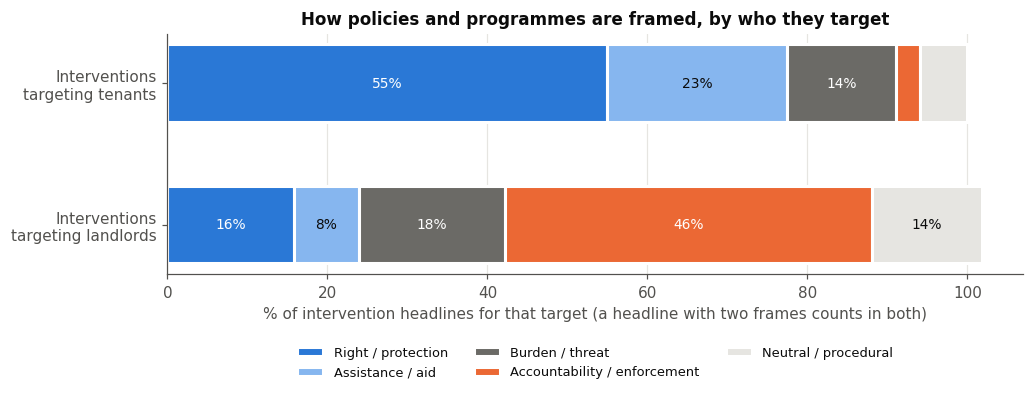

In [16]:
fig, ax = plt.subplots(figsize=(9.5, 3.9))
order = ["tenants", "landlords"]
cols = {"protective": "#2a78d6", "assistance": "#86b6ef", "burden_threat": "#6b6a66", "accountability": "#eb6834", "neutral": "#e6e5e1"}
lab = {"protective": "Right / protection", "assistance": "Assistance / aid", "burden_threat": "Burden / threat", "accountability": "Accountability / enforcement", "neutral": "Neutral / procedural"}
left = np.zeros(2)
for fr_ in FRAME_KEYS:
    vals = np.array([q1_frames[(q1_frames["target"] == o) & (q1_frames["frame"] == fr_)]["rate"].iloc[0] * 100 for o in order])
    ax.barh(["Interventions\ntargeting tenants", "Interventions\ntargeting landlords"][::-1], vals[::-1], left=left, color=cols[fr_], edgecolor="white", linewidth=2, height=0.55, label=lab[fr_])
    for i, (v, l0) in enumerate(zip(vals[::-1], left)):
        if v >= 7:
            ax.text(l0 + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if fr_ in ("protective", "burden_threat", "accountability") else INK)
    left += vals[::-1]
ax.set_xlabel("% of intervention headlines for that target (a headline with two frames counts in both)")
ax.set_title("How policies and programmes are framed, by who they target")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25), fontsize=8.5)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [17]:
examples_block(Q1, [
    ("Protection or rights framed for tenants", (Q1["intervention_frame"].str.contains("protective")) & (Q1["intervention_target"] == "t"), 3),
    ("Burden or threat attributed to a landlord-side speaker", (Q1["intervention_frame"].str.contains("burden")) & (Q1["burden_voice"] == "att") & Q1["intervention_target"].isin(["l", "b"]), 3),
    ("Policy burden on tenants (own voice or attributed)", (Q1["intervention_frame"].str.contains("burden")) & (Q1["intervention_target"] == "t"), 2),
    ("Assistance directed at landlords", (Q1["intervention_frame"].str.contains("assistance")) & (Q1["intervention_target"] == "l"), 2)],
    cols=["intervention_frame", "intervention_target", "burden_voice"])

,category,group,title,media_name,publish_date,url,intervention_frame,intervention_target,burden_voice
0,Protection or rights framed for tenants (n=41),headline,"California tenants rise up, demand rent caps from city halls",thestar.com,2022-11-05,https://www.thestar.com/life/2022/11/05/california-tenants-rise-up-demand-rent-caps-f,protective,t,-
1,Protection or rights framed for tenants (n=41),headline,We're not making big bucks': Renter supports cap,tj.news,2022-03-25,https://tj.news/kings-county-record/101829777?ref=rss,protective,t,-
2,Protection or rights framed for tenants (n=41),headline,"Rent doubles for tenants of 2 west-end Toronto condos, province says reform coming",globalnews.ca,2017-04-04,http://globalnews.ca/news/3355767/toronto-rent-doubles-rent-control/,protective,t,-
3,Burden or threat attributed to a landlord-side speaker (n=18),headline,Landlord not happy with Residential Tenancies program policy,globalnews.ca,2015-11-26,http://globalnews.ca/news/2364525/landlord-not-happy-with-residential-tenancies-progr,burden_threat,l,att
4,Burden or threat attributed to a landlord-side speaker (n=18),headline,We’ve been pinched landlords for 30 years. It’s time for rent control and the Landlord Tenant Board to get a serious o,thestar.com,2023-04-14,https://www.thestar.com/opinion/contributors/2023/04/14/why-landlord-and-tenant-laws-,burden_threat,l,att
5,Burden or threat attributed to a landlord-side speaker (n=18),headline,Windsor landlords protest rental licencing pilot project,ctvnews.ca,2023-03-21,https://windsor.ctvnews.ca/property-owners-protest-windsor-s-rental-licencing-pilot-p,burden_threat,l,att
6,Policy burden on tenants (own voice or attributed) (n=10),headline,Dickensian approach to residential tenants lingers in Australian law,theconversation.com,2016-09-13,http://theconversation.com/dickensian-approach-to-residential-tenants-lingers-in-aust,burden_threat,t,own
7,Policy burden on tenants (own voice or attributed) (n=10),headline,Manitoba government hiking rent for some tenants in public housing,cbc.ca,2017-05-03,http://www.cbc.ca/news/canada/manitoba/manitoba-housing-rent-increase-1.4170363?cmp=r,burden_threat,t,own
8,Assistance directed at landlords (n=7),headline,Green program expands to help landlords reduce carbon footprint,cbc.ca,2016-08-25,http://www.cbc.ca/news/canada/sudbury/landlords-going-green-1.3735903?cmp=rss,assistance,l,-
9,Assistance directed at landlords (n=7),headline,Why is Canada subsidizing landlords during a housing crisis?,canadiandimension.com,2024-11-01,https://canadiandimension.com/articles/view/why-is-canada-subsidizing-landlords-durin,assistance,l,own


In [18]:
fr = q1_frames.set_index(["target", "frame"])


def pct(t, f):
    return f"{100 * fr.loc[(t, f), 'rate']:.0f}% ({100 * fr.loc[(t, f), 'lo']:.0f}–{100 * fr.loc[(t, f), 'hi']:.0f})"


bl = iv[iv["burden_threat"] & iv["intervention_target"].isin(["l", "b"])]
nonb = iv[~iv["burden_threat"] & iv["intervention_target"].eq("l")]
n_att, n_b = int((bl["burden_voice"] == "att").sum()), len(bl)
hum_b, hum_n = int((bl["humanizing"] == "l").sum()), int((nonb["humanizing"] == "l").sum())
Q1_RES = {"t_prot": fr.loc[("tenants", "protective"), "rate"], "t_assist": fr.loc[("tenants", "assistance"), "rate"], "l_burden": fr.loc[("landlords", "burden_threat"), "rate"],
          "l_acc": fr.loc[("landlords", "accountability"), "rate"], "t_burden": fr.loc[("tenants", "burden_threat"), "rate"], "n_att": n_att, "n_b": n_b, "hum_b": hum_b, "hum_n": hum_n, "nonb_n": len(nonb)}
nec_t, nec_l = int((Q1["necessity"] == "tH").sum()), int((Q1["necessity"] == "lH").sum())
display(Markdown(f"""**Takeaway (Q1).** Policy headlines aimed at tenants are framed mostly as **rights or protection** ({pct('tenants', 'protective')}) rather than **assistance** ({pct('tenants', 'assistance')}), and only {pct('tenants', 'burden_threat')} present a policy as a burden on tenants, so in this sample the "tenants as recipients of charity" frame is not the dominant one. Headlines aimed at landlords are framed mostly as **accountability** ({pct('landlords', 'accountability')}); {pct('landlords', 'burden_threat')} are framed as a **burden or threat to landlords**, and {n_att} of {n_b} burden headlines about landlords (or both groups) attribute the claim to a landlord-side speaker rather than stating it in the headline's own voice. Personal-hardship detail about a landlord appears in {hum_b} of those {n_b} burden headlines but in only {hum_n} of {len(nonb)} other landlord-targeted policy headlines: a small, striking co-occurrence that matches the reported-commentary hypothesis, at counts too small to call a corpus pattern. Constraint language is rare ({nec_t} about tenants, {nec_l} about landlords) and differs in kind: for tenants it describes being displaced ("forced from", "has to move out"), for landlords it describes legal obligations ("must hold increases", "have till").

*Alternative explanations.* Who a policy "targets" is fixed by what governments did (rent caps and eviction bans protect tenants; licensing regulates landlords), so these proportions partly reflect the policy agenda, not editorial choice. The intervals are wide ({int(q1_n.get('tenants', 0))} tenant-targeted and {int(q1_n.get('landlords', 0))} landlord-targeted intervention headlines). Q1 does not show tenants' interests being delegitimised; it shows a **landlord-side burden narrative that exists, is mostly attributed, and sometimes carries personal hardship detail.**"""))

**Takeaway (Q1).** Policy headlines aimed at tenants are framed mostly as **rights or protection** (55% (43–67)) rather than **assistance** (23% (13–33)), and only 14% (6–22) present a policy as a burden on tenants, so in this sample the "tenants as recipients of charity" frame is not the dominant one. Headlines aimed at landlords are framed mostly as **accountability** (46% (36–56)); 18% (10–27) are framed as a **burden or threat to landlords**, and 18 of 23 burden headlines about landlords (or both groups) attribute the claim to a landlord-side speaker rather than stating it in the headline's own voice. Personal-hardship detail about a landlord appears in 5 of those 23 burden headlines but in only 0 of 75 other landlord-targeted policy headlines: a small, striking co-occurrence that matches the reported-commentary hypothesis, at counts too small to call a corpus pattern. Constraint language is rare (6 about tenants, 4 about landlords) and differs in kind: for tenants it describes being displaced ("forced from", "has to move out"), for landlords it describes legal obligations ("must hold increases", "have till").

*Alternative explanations.* Who a policy "targets" is fixed by what governments did (rent caps and eviction bans protect tenants; licensing regulates landlords), so these proportions partly reflect the policy agenda, not editorial choice. The intervals are wide (73 tenant-targeted and 92 landlord-targeted intervention headlines). Q1 does not show tenants' interests being delegitimised; it shows a **landlord-side burden narrative that exists, is mostly attributed, and sometimes carries personal hardship detail.**

## 8. Question 2 · How are credibility, blame and deservingness assigned?

**Mechanism and observable tests.** Not epithet counts: the code separates **who asserts a judgment** (`own` voice, `attributed` to a source, or `rejected`) from **what kind** it is: a legal **finding or sanction** (fined, convicted), an **evaluative label** ("bad", "nightmare", "slum", "deadbeat"), a **class-level generalisation** (about tenants or landlords as a type), or a described **misconduct** (an act). Accurate reports of wrongdoing are not treated as unfair; the question is how *judgments and generalisations* are distributed. Reported-speech wording (says / claims / reveals) is compared for the two groups as wording, **not** as credibility. Non-payment is characterised by motive where the headline gives one (a census follows the sample).

In [19]:
Q2["own_judgment"] = Q2["blame_status"].eq("O") & Q2["blame_type"].isin(["E", "G"])
Q2["finding"] = Q2["blame_status"].eq("O") & Q2["blame_type"].eq("F")
Q2["attrib"] = Q2["blame_status"].eq("A")
Q2["any_blame"] = Q2["blame_status"].isin(["O", "A", "R"])
Q2["has_speech"] = Q2["claim_wording"] != "-"
Q2["hedged"] = Q2["claim_wording"].eq("H")
Q2["class_level"] = Q2["blame_type"].eq("G")
Q2["sanction_or_allegation"] = Q2["finding"] | Q2["attrib"]
q2_rows = []
for key, label, den in [("any_blame", "Any blame, judgment or sanction", None), ("own_judgment", "Own-voice evaluative label or generalisation", None),
                        ("class_level", "Class-level generalisation (any voice)", None), ("finding", "Own-voice legal finding or sanction (fined, convicted…)", None),
                        ("attrib", "Attributed allegation, charge or accusation", None), ("hedged", "Hedged wording ('claims', 'alleges') among reported speech", "has_speech")]:
    for g in ["tenant", "landlord"]:
        sub = Q2[Q2["group"] == g]
        r = wrate(sub, key, den=den)
        q2_rows.append({"measure": label, "group": g, **r})
q2r = pd.DataFrame(q2_rows)
lbound = {g: cand["Q2"].groupby("group").size()[g] / n_prim[g] for g in ["tenant", "landlord"]}
q2_tab = q2r.assign(cell=lambda d: [f"{100 * r.rate:.1f}% ({100 * r.lo:.1f}–{100 * r.hi:.1f}) · {r.k}/{r.n}" for r in d.itertuples()]).pivot(index="measure", columns="group", values="cell")
print("Rates among candidate observations of each group (weighted; 95% CI; coded count / denominator):")
display(q2_tab.reindex([m for m in q2r["measure"].unique()])[["tenant", "landlord"]])
d_judg = wdiff(Q2[Q2["group"] == "tenant"], Q2[Q2["group"] == "landlord"], "own_judgment")
d_find = wdiff(Q2[Q2["group"] == "tenant"], Q2[Q2["group"] == "landlord"], "finding")
d_att = wdiff(Q2[Q2["group"] == "tenant"], Q2[Q2["group"] == "landlord"], "attrib")
print(f"Tenant − landlord (pp): own-voice judgment {d_judg['diff_pp']:+.1f} ({d_judg['lo_pp']:+.1f} to {d_judg['hi_pp']:+.1f}); "
      f"legal finding {d_find['diff_pp']:+.1f} ({d_find['lo_pp']:+.1f} to {d_find['hi_pp']:+.1f}); attributed allegation {d_att['diff_pp']:+.1f} ({d_att['lo_pp']:+.1f} to {d_att['hi_pp']:+.1f})")
print("\nReported-speech wording, counts by group (P plain, H hedged, F factive):")
display(pd.crosstab(Q2[Q2["has_speech"]]["group"], Q2[Q2["has_speech"]]["claim_wording"]))

Rates among candidate observations of each group (weighted; 95% CI; coded count / denominator):


group,tenant,landlord
measure,,
"Any blame, judgment or sanction",20.7% (14.0–27.3) · 31/150,40.7% (33.3–48.7) · 61/150
Own-voice evaluative label or generalisation,8.0% (4.0–12.7) · 12/150,8.7% (4.7–13.3) · 13/150
Class-level generalisation (any voice),2.7% (0.7–5.3) · 4/150,9.3% (4.7–14.0) · 14/150
"Own-voice legal finding or sanction (fined, convicted…)",2.7% (0.7–5.3) · 4/150,13.3% (8.0–19.3) · 20/150
"Attributed allegation, charge or accusation",8.0% (4.0–12.0) · 12/150,16.7% (11.3–22.7) · 25/150
"Hedged wording ('claims', 'alleges') among reported speech",6.2% (1.5–12.7) · 4/64,2.3% (0.0–8.0) · 1/43


Tenant − landlord (pp): own-voice judgment -0.7 (-6.8 to +5.5); legal finding -10.7 (-16.2 to -5.1); attributed allegation -8.7 (-15.6 to -1.7)

Reported-speech wording, counts by group (P plain, H hedged, F factive):


claim_wording,F,H,P
group,,,
landlord,1,1,41
tenant,0,4,60


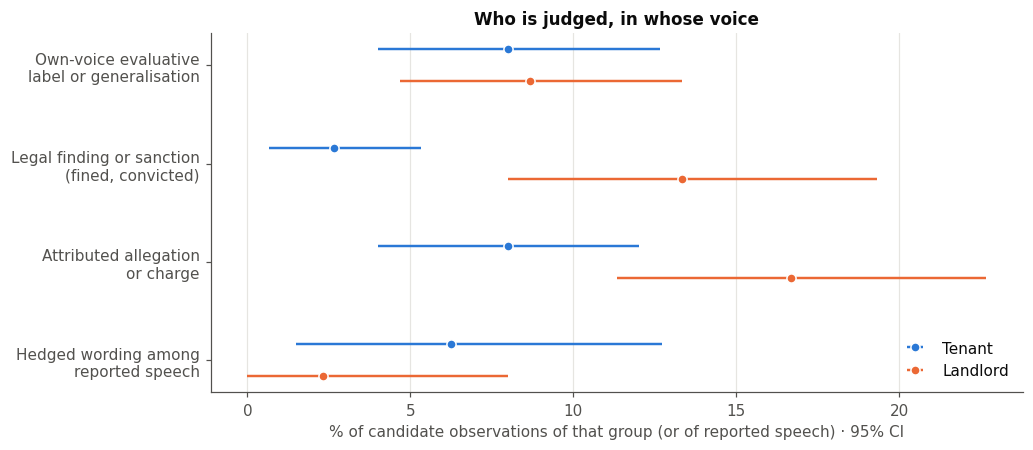

In [20]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
meas = ["Own-voice evaluative label or generalisation", "Own-voice legal finding or sanction (fined, convicted…)", "Attributed allegation, charge or accusation", "Hedged wording ('claims', 'alleges') among reported speech"]
y = np.arange(len(meas))[::-1]
for g, dy in [("tenant", 0.16), ("landlord", -0.16)]:
    d = q2r[q2r["group"] == g].set_index("measure").loc[meas]
    ax.errorbar(100 * d["rate"], y + dy, xerr=[100 * (d["rate"] - d["lo"]), 100 * (d["hi"] - d["rate"])], fmt="o", color=COLORS[g], ms=6, lw=1.6, mec="white", label=g.capitalize())
ax.set_yticks(y); ax.set_yticklabels(["Own-voice evaluative\nlabel or generalisation", "Legal finding or sanction\n(fined, convicted)", "Attributed allegation\nor charge", "Hedged wording among\nreported speech"])
ax.set_xlabel("% of candidate observations of that group (or of reported speech) · 95% CI")
ax.set_title("Who is judged, in whose voice")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [21]:
examples_block(Q2, [
    ("Own-voice evaluative label or generalisation about TENANTS", Q2["own_judgment"] & (Q2["group"] == "tenant"), 3),
    ("Own-voice evaluative label or generalisation about LANDLORDS", Q2["own_judgment"] & (Q2["group"] == "landlord"), 3),
    ("Hedged wording ('claims', 'alleges')", Q2["hedged"], 2),
    ("Landlord legal finding or sanction (own voice)", Q2["finding"] & (Q2["group"] == "landlord"), 2)],
    cols=["blame_status", "blame_type", "claim_wording"])

,category,group,title,media_name,publish_date,url,blame_status,blame_type,claim_wording
0,Own-voice evaluative label or generalisation about TENANTS (n=12),tenant,"Terrible, tenacious, Toronto tenants meet their match",thestar.com,2015-09-11,http://www.thestar.com/news/gta/2015/09/11/terrible-tenacious-toronto-tenants-meet-th,O,E,-
1,Own-voice evaluative label or generalisation about TENANTS (n=12),tenant,Too tough to evict TCHC's thug tenants,torontosun.com,2017-03-05,http://www.torontosun.com/2017/03/05/too-tough-to-evict-tchcs-thug-tenants,O,G,-
2,Own-voice evaluative label or generalisation about TENANTS (n=12),tenant,"Paradise homeowner spends month picking up needles, renovating after nightmare tenants",cbc.ca,2017-06-10,http://www.cbc.ca/news/canada/newfoundland-labrador/paradise-residential-tenancies-ac,O,E,-
3,Own-voice evaluative label or generalisation about LANDLORDS (n=13),landlord,Toronto considers apartment licensing to crack down on bad landlords,thestar.com,2016-04-09,http://www.thestar.com/news/gta/2016/04/09/toronto-considers-apartment-licensing-to-c,O,G,-
4,Own-voice evaluative label or generalisation about LANDLORDS (n=13),landlord,Bad landlords in Kelowna feel city's wrath,kelownadailycourier.ca,2020-11-10,http://www.kelownadailycourier.ca/news/article_a97d16a8-2396-11eb-8219-6fb6f453cb9d.h,O,G,-
5,Own-voice evaluative label or generalisation about LANDLORDS (n=13),landlord,Creepy Kansas landlord accused of evicting female tenants who wouldn’t have sex with him,torontosun.com,2017-12-20,http://torontosun.com/news/world/creepy-kansas-landlord-accused-of-evicting-female-te,O,E,-
6,"Hedged wording ('claims', 'alleges') (n=5)",tenant,Toronto tenants claim landlord raised rents to pay for capital repairs,ctvnews.ca,2020-02-11,https://toronto.ctvnews.ca/toronto-tenants-claim-landlord-raised-rents-to-pay-for-cap,-,-,H
7,"Hedged wording ('claims', 'alleges') (n=5)",tenant,Mission tenants claim to be left out in cold after apartment fire displaces 82 people,abbynews.com,2020-11-13,https://www.abbynews.com/news/mission-tenants-claim-to-be-left-out-in-cold-after-apar,-,-,H
8,Landlord legal finding or sanction (own voice) (n=20),landlord,Landlord ordered to pay back Toronto students $5K after listing their rented rooms on Airbnb,cbc.ca,2018-09-06,https://www.cbc.ca/news/canada/toronto/students-warn-of-landlord-charging-double-rent,O,F,-
9,Landlord legal finding or sanction (own voice) (n=20),landlord,Landlord fined for discrimination against social assistance recipient,winnipegfreepress.com,2019-03-20,https://www.winnipegfreepress.com/local/landlord-fined-for-discrimination-against-wom,O,F,-


In [22]:
def ci_txt(r):
    return f"{100 * r['rate']:.1f}% ({100 * r['lo']:.1f}–{100 * r['hi']:.1f})"


g_ = {(m, g): q2r[(q2r["measure"] == m) & (q2r["group"] == g)].iloc[0] for m in q2r["measure"].unique() for g in ["tenant", "landlord"]}
M_J = "Own-voice evaluative label or generalisation"
n_h_t, n_h_l = int(Q2[(Q2["group"] == "tenant") & Q2["hedged"]].shape[0]), int(Q2[(Q2["group"] == "landlord") & Q2["hedged"]].shape[0])
Q2_RES = {"judg": d_judg, "find": d_find, "att": d_att, "n_h_t": n_h_t, "n_h_l": n_h_l}
display(Markdown(f"""**Takeaway (Q2).** In the headline's own voice, **tenants and landlords are labelled or generalised about at similar rates** ({ci_txt(g_[(M_J, 'tenant')])} vs {ci_txt(g_[(M_J, 'landlord')])}; difference {d_judg['diff_pp']:+.1f} pp, CI {d_judg['lo_pp']:+.1f} to {d_judg['hi_pp']:+.1f}). The kind differs: labels about tenants are mostly about specific tenants ("nightmare", "thug", "professional" tenant), whereas labels about landlords are more often class-level ("bad landlords", "neglectful landlords", often in enforcement stories). **Landlords carry more sanctions and allegations**: own-voice legal findings {d_find['a']['rate'] * 100:.1f}% (tenants) vs {d_find['b']['rate'] * 100:.1f}% (landlords), attributed allegations {d_att['a']['rate'] * 100:.1f}% vs {d_att['b']['rate'] * 100:.1f}%. Hedged wording ('claims', 'alleges') appears in {n_h_t} tenant and {n_h_l} landlord reported-speech headlines, too few to say anything about differential scepticism. This line is **closed as a tenant-disadvantaging asymmetry in the headline's own judgments**: the data point, if anywhere, the other way on sanctions.

*Alternative explanations.* Sanctions and charges are accurate reports and follow what courts and tribunals do; an enforcement agenda (licensing, "bad landlords") also generates class-level labels. Rates are conditional on retrieval (blame cues, reported speech, non-payment wording), so the lower-bound share of all primary observations with an own-voice evaluative label or generalisation is only about {100 * lbound['tenant'] * g_[(M_J, 'tenant')]['rate']:.1f}% (tenants) and {100 * lbound['landlord'] * g_[(M_J, 'landlord')]['rate']:.1f}% (landlords)."""))

**Takeaway (Q2).** In the headline's own voice, **tenants and landlords are labelled or generalised about at similar rates** (8.0% (4.0–12.7) vs 8.7% (4.7–13.3); difference -0.7 pp, CI -6.8 to +5.5). The kind differs: labels about tenants are mostly about specific tenants ("nightmare", "thug", "professional" tenant), whereas labels about landlords are more often class-level ("bad landlords", "neglectful landlords", often in enforcement stories). **Landlords carry more sanctions and allegations**: own-voice legal findings 2.7% (tenants) vs 13.3% (landlords), attributed allegations 8.0% vs 16.7%. Hedged wording ('claims', 'alleges') appears in 4 tenant and 1 landlord reported-speech headlines, too few to say anything about differential scepticism. This line is **closed as a tenant-disadvantaging asymmetry in the headline's own judgments**: the data point, if anywhere, the other way on sanctions.

*Alternative explanations.* Sanctions and charges are accurate reports and follow what courts and tribunals do; an enforcement agenda (licensing, "bad landlords") also generates class-level labels. Rates are conditional on retrieval (blame cues, reported speech, non-payment wording), so the lower-bound share of all primary observations with an own-voice evaluative label or generalisation is only about 1.4% (tenants) and 2.3% (landlords).

### Non-payment: how is it characterised?

Non-payment is where deservingness is most directly at stake, and a rare event in headlines, so a **census** replaces sampling: every primary-sample headline matching a corrected non-payment pattern (arrears, unpaid rent, owes, stopped paying, rent strike, withholds rent, rent-free…) was read and coded for whose non-payment it is and for the **motive given**: inability or hardship, refusal or exploitation, collective withholding (a rent strike), justified by conditions, disputed, or unspecified. Headlines about a landlord's debts, commercial tenants and rent-freeze policy are set aside. (The Q2 candidate pool used an earlier pattern with a substring flaw, "owing" matching "following" and "growing". It was kept as drawn, which adds a few irrelevant candidates and slightly dilutes Q2 rates; the census uses the corrected pattern.)

Census retrieval reproduces the coded set: True (121 headlines retrieved)
121 headlines retrieved; 94 are about tenants' non-payment (27 set aside). Motive given, by voice:


nonpay_voice,attributed (e.g. landlord says),headline's own voice,no characterisation,total
nonpay_motive,,,,
collective withholding (rent strike),0,0,41,41
unspecified,8,1,21,30
refusal or exploitation,6,10,0,16
inability or hardship,1,3,0,4
justified by conditions,0,0,2,2
disputed,1,0,0,1


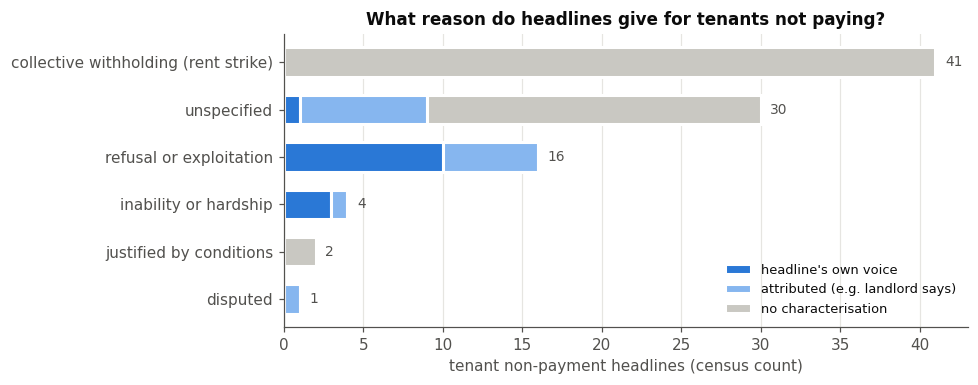

In [23]:
NP_PAT = re.compile(NONPAY.pattern.replace("|owing", r"|\bowing\b"), re.I)
NP_EXTRA = re.compile(r"in arrears|rent arrears|fell behind|behind on (?:the )?rent|can'?t pay (?:the )?rent|unable to pay rent|rent debt|owes? (?:\$|\w+ rent)|skipp\w+ out on rent|rent[- ]free|stop(?:ped)? paying|not paying rent|non-?paying", re.I)
Hprim = main.drop_duplicates("family_id_near").sort_values("family_id_near")
np_fams = list(Hprim[Hprim["title"].str.contains(NP_PAT) | Hprim["title"].str.contains(NP_EXTRA)]["family_id_near"])
np_cached = cr[cr["question"] == "NP"].drop_duplicates("sample_key")["family_id_near"].tolist()
print("Census retrieval reproduces the coded set:", set(np_fams) == set(np_cached), f"({len(np_fams)} headlines retrieved)")
npc = cr[cr["question"] == "NP"].pivot(index=["sample_key", "family_id_near"], columns="field", values="value").reset_index()
npc = npc.join(main.drop_duplicates("family_id_near").set_index("family_id_near")[["title", "url", "publish_date", "media_name", "year"]], on="family_id_near")
tn = npc[npc["nonpay_payer"] == "t"].copy()
MOT = {"C": "collective withholding (rent strike)", "U": "unspecified", "R": "refusal or exploitation", "I": "inability or hardship", "J": "justified by conditions", "D": "disputed"}
VOICE = {"O": "headline's own voice", "A": "attributed (e.g. landlord says)", "-": "no characterisation"}
vo = pd.crosstab(tn["nonpay_motive"].map(MOT), tn["nonpay_voice"].map(VOICE)).reindex(list(MOT.values())).fillna(0).astype(int)
print(f"{len(npc)} headlines retrieved; {len(tn)} are about tenants' non-payment ({len(npc) - len(tn)} set aside). Motive given, by voice:")
display(vo.assign(total=lambda d: d.sum(axis=1)))
n_ref, n_inab = int((tn["nonpay_motive"] == "R").sum()), int((tn["nonpay_motive"] == "I").sum())
NP_RES = {"n_tn": len(tn), "n_ref": n_ref, "n_inab": n_inab, "n_coll": int((tn["nonpay_motive"] == "C").sum()), "n_unspec": int((tn["nonpay_motive"] == "U").sum()),
          "n_ref_own": int(((tn["nonpay_motive"] == "R") & (tn["nonpay_voice"] == "O")).sum()), "n_inab_own": int(((tn["nonpay_motive"] == "I") & (tn["nonpay_voice"] == "O")).sum()),
          "n_indiv": int(tn["nonpay_motive"].isin(["R", "I", "J", "D"]).sum())}
fig, ax = plt.subplots(figsize=(9, 3.6))
ycat = list(MOT.values())[::-1]
left = np.zeros(len(ycat))
for col, color in [("headline's own voice", "#2a78d6"), ("attributed (e.g. landlord says)", "#86b6ef"), ("no characterisation", "#c9c8c2")]:
    v = vo.reindex(ycat)[col].to_numpy() if col in vo else np.zeros(len(ycat))
    ax.barh(ycat, v, left=left, color=color, edgecolor="white", linewidth=2, height=0.62, label=col)
    left += v
for i, tot in enumerate(left):
    ax.text(tot + 0.6, i, f"{int(tot)}", va="center", fontsize=9, color=MUTED)
ax.set_xlabel("tenant non-payment headlines (census count)"); ax.set_title("What reason do headlines give for tenants not paying?")
ax.legend(loc="lower right", fontsize=8.5); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [24]:
examples_block(tn.assign(group="tenant"), [
    ("Individual non-payment framed as refusal or exploitation", tn["nonpay_motive"].eq("R"), 4),
    ("Non-payment framed as inability or hardship", tn["nonpay_motive"].eq("I"), 3),
    ("Non-payment framed as justified by conditions or disputed", tn["nonpay_motive"].isin(["J", "D"]), 2)], cols=["nonpay_motive", "nonpay_voice"])
display(Markdown(f"""**Takeaway (non-payment).** Of {NP_RES['n_tn']} headlines about tenants' non-payment, **{NP_RES['n_coll']} are rent strikes** (collective withholding), {NP_RES['n_unspec']} give no motive, and {NP_RES['n_indiv']} characterise an individual tenant's motive (refusal, inability, justification or dispute). **{NP_RES['n_ref']} frame it as refusal or exploitation ({NP_RES['n_ref_own']} of them in the headline's own voice) against {NP_RES['n_inab']} that frame it as inability or hardship** ({NP_RES['n_inab_own']} in the headline's own voice). Where an individual motive is given, refusal is therefore described about {NP_RES['n_ref'] / max(NP_RES['n_inab'], 1):.0f} times as often as inability. *Alternatives:* these are news items. Enforcement, fraud and eviction-hearing stories are where an individual's motive is reported, while hardship-driven arrears tend to appear as aggregate statistics ("one in five households fell behind") that give no individual motive; a retrieval built on non-payment words also under-catches hardship phrased as affordability. This is a narrow, countable pattern, **supported in this read-through but not a validated corpus estimate**, and whether the motive in a headline matches the article needs article-level follow-up."""))

,category,group,title,media_name,publish_date,url,nonpay_motive,nonpay_voice
0,Individual non-payment framed as refusal or exploitation (n=16),tenant,Tenants dodging the system to live rent free,torontosun.com,2017-01-11,http://www.torontosun.com/2017/01/11/tenants-dodging-the-system-to-live-rent-free,R,O
1,Individual non-payment framed as refusal or exploitation (n=16),tenant,North Bay news: Rent-free for a year: Nightmare tenant victimizes couple,ctvnews.ca,2023-06-21,https://northernontario.ctvnews.ca/rent-free-for-a-year-nightmare-tenant-victimizes-n,R,O
2,Individual non-payment framed as refusal or exploitation (n=16),tenant,Alberta landlord struggling to evict man living rent-free on his driveway,globalnews.ca,2017-11-01,https://globalnews.ca/news/3838405/alberta-landlord-struggling-to-evict-man-living-re,R,A
3,Individual non-payment framed as refusal or exploitation (n=16),tenant,Toronto's 'professional tenant' found guilty of fraud for skipping out on rent for 2 years,cbc.ca,2019-06-25,https://www.cbc.ca/news/canada/toronto/guilty-toronto-james-regan-3-counts-1.5189852?,R,O
4,Non-payment framed as inability or hardship (n=4),tenant,"Sask. tenants $30M in arrears because of COVID-19, eviction ban, landlord association says",ctvnews.ca,2020-07-08,https://saskatoon.ctvnews.ca/sask-tenants-30m-in-arrears-because-of-covid-19-eviction,I,A
5,Non-payment framed as inability or hardship (n=4),tenant,"Tenants behind on rent in pandemic face harassment, eviction",thestar.com,2020-06-14,https://www.thestar.com/news/world/us/2020/06/14/tenants-behind-on-rent-in-pandemic-f,I,O
6,Non-payment framed as inability or hardship (n=4),tenant,7.6M in rent arrears pile up on London tenants as working poor struggle,lfpress.com,2021-02-19,https://lfpress.com/news/local-news/7-6m-in-rent-arrears-pile-up-on-london-tenants-as,I,O
7,Non-payment framed as justified by conditions or disputed (n=3),tenant,More Toronto landlords trying to evict tenants for not paying rent even when they've paid in full: advocates,cbc.ca,2025-09-25,https://www.cbc.ca/news/canada/toronto/toronto-landlords-evictions-rent-loophole-1.76,D,A
8,Non-payment framed as justified by conditions or disputed (n=3),tenant,Calgary tenant evicted for not paying rent after apartment floods numerous times,ctvnews.ca,2019-11-26,https://calgary.ctvnews.ca/calgary-tenant-evicted-for-not-paying-rent-after-apartment,J,-


**Takeaway (non-payment).** Of 94 headlines about tenants' non-payment, **41 are rent strikes** (collective withholding), 30 give no motive, and 23 characterise an individual tenant's motive (refusal, inability, justification or dispute). **16 frame it as refusal or exploitation (10 of them in the headline's own voice) against 4 that frame it as inability or hardship** (3 in the headline's own voice). Where an individual motive is given, refusal is therefore described about 4 times as often as inability. *Alternatives:* these are news items. Enforcement, fraud and eviction-hearing stories are where an individual's motive is reported, while hardship-driven arrears tend to appear as aggregate statistics ("one in five households fell behind") that give no individual motive; a retrieval built on non-payment words also under-catches hardship phrased as affordability. This is a narrow, countable pattern, **supported in this read-through but not a validated corpus estimate**, and whether the motive in a headline matches the article needs article-level follow-up.

## 9. Question 3 · How are harms explained and responsibility made visible?

**Mechanism and observable tests.** Within tenant-harm headlines about **eviction, rent increases or housing conditions** (fires, floods and crime are excluded because responsibility cannot be inferred), does the headline (a) **name a decision-maker or responsible actor**, and (b) give an **explicit reason, policy or institutional context, market or financial mechanism, or wider housing condition**, or is it an isolated event with no stated cause? The test measures **explicit headline context only**: a headline that omits an actor is not called structurally silent about the article, and headline length, topic and the information available may explain an omission. Landlords and tenants are not interchangeable roles, so comparisons are made *within* tenant-harm headlines (by event type, by whether the landlord is also named in the headline, and by outlet), not between the groups.

In [25]:
Q3["assessable"] = Q3["actor_named"] != "x"
Q3["actor"] = Q3["actor_named"].eq("1")
Q3["wide"] = Q3["explanation"].str.contains("[PMC]", regex=True)
Q3["reason_only"] = Q3["explanation"].str.contains("R") & ~Q3["wide"]
Q3["no_explanation"] = Q3["explanation"].eq("N")
ev_flags = main[main["group"] == "tenant"].set_index("family_id_near")[["r_event_evict", "r_event_rent", "r_event_cond"]]
Q3 = Q3.join(ev_flags, on="family_id_near")
Q3["event"] = np.select([Q3["r_event_evict"] == True, Q3["r_event_rent"] == True, Q3["r_event_cond"] == True], ["eviction", "rent increase", "housing conditions"], "other")
a3 = Q3[Q3["assessable"]]
print(f"{len(a3)} of {len(Q3)} coded headlines were assessable ({len(Q3) - len(a3)} set aside as incidents, commercial or not a tenant-harm event).")
tab3 = []
for scope, sub in [("tenant-only headlines", a3[a3["mention_group"] == "tenant"]), ("headlines also naming the landlord", a3[a3["mention_group"] == "both"])]:
    rr = {"actor named": wrate(sub, "actor"), "wider mechanism (policy, market or conditions)": wrate(sub, "wide"), "reason or cause only": wrate(sub, "reason_only"),
          "no explanation at all": wrate(sub, "no_explanation")}
    for k, r in rr.items():
        tab3.append({"scope": scope, "measure": k, "cell": fmt(r)})
display(pd.DataFrame(tab3).pivot(index="measure", columns="scope", values="cell")[["tenant-only headlines", "headlines also naming the landlord"]])
solo = a3[a3["mention_group"] == "tenant"]
print("Tenant-only headlines by event type (coded sample counts):")
display(solo.groupby("event").agg(n=("actor", "size"), actor_named=("actor", "sum"), wider_mechanism=("wide", "sum"), reason_only=("reason_only", "sum"), no_explanation=("no_explanation", "sum")))
rule_actor = main[main["group"] == "tenant"].set_index("family_id_near")["r_actor_named"].reindex(solo["family_id_near"]).to_numpy()
RULE_ACTOR_AGREE = 100 * (solo['actor'].to_numpy() == rule_actor).mean()
print(f"Rule flag 'actor named' agrees with the coded value in {RULE_ACTOR_AGREE:.0f}% of tenant-only assessable headlines; the rule is used below only for a relative outlet comparison.")

179 of 200 coded headlines were assessable (21 set aside as incidents, commercial or not a tenant-harm event).


scope,tenant-only headlines,headlines also naming the landlord
measure,,
actor named,21.6% (14.7–28.4) · 25/116,95.2% (88.9–100.0) · 60/63
no explanation at all,47.4% (37.9–56.0) · 55/116,34.9% (23.8–47.6) · 22/63
reason or cause only,9.5% (4.3–14.7) · 11/116,19.0% (9.5–28.6) · 12/63
"wider mechanism (policy, market or conditions)",43.1% (34.5–52.6) · 50/116,46.0% (33.3–58.7) · 29/63


Tenant-only headlines by event type (coded sample counts):


,n,actor_named,wider_mechanism,reason_only,no_explanation
event,,,,,
eviction,74,18,37,10,27
housing conditions,27,6,7,1,19
rent increase,15,1,6,0,9


Rule flag 'actor named' agrees with the coded value in 80% of tenant-only assessable headlines; the rule is used below only for a relative outlet comparison.


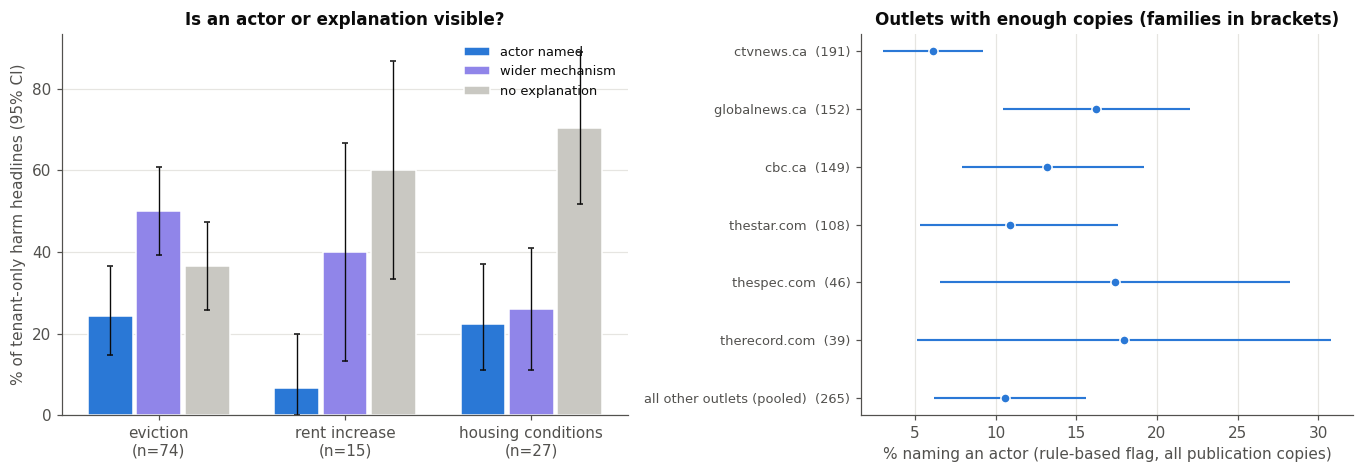

In [26]:
# outlet comparison over publication copies (rule-based flag, family-clustered CI); tenant-only headlines in the primary sample
copies_t = OBS[(OBS["group"] == "tenant") & (OBS["mention_group"] == "tenant") & OBS["relevance"].isin(PRIMARY_RELEVANCE) & OBS["r_q3_den"]].copy()
top_out = copies_t["media_name"].value_counts()
top_out = top_out[top_out >= MIN_CELL].head(7).index.tolist()


def cluster_rate(df, flag, cluster="family_id_near", B=N_BOOT_SMALL, seed=SEED):
    codes, uniq = pd.factorize(df[cluster])
    n, k = np.bincount(codes, minlength=len(uniq)).astype(float), np.bincount(codes, weights=df[flag].astype(float).to_numpy(), minlength=len(uniq))
    idx = np.random.default_rng(seed).integers(0, len(uniq), size=(B, len(uniq)))
    d = k[idx].sum(1) / n[idx].sum(1)
    return {"rate": k.sum() / n.sum(), "lo": np.quantile(d, 0.025), "hi": np.quantile(d, 0.975), "k": int(k.sum()), "n": int(n.sum()), "families": len(uniq)}


out_rows = [{"outlet": o, **cluster_rate(copies_t[copies_t["media_name"] == o], "r_actor_named")} for o in top_out]
out_rows.append({"outlet": "all other outlets (pooled)", **cluster_rate(copies_t[~copies_t["media_name"].isin(top_out)], "r_actor_named")})
q3_out = pd.DataFrame(out_rows)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
evs = ["eviction", "rent increase", "housing conditions"]
x = np.arange(len(evs))
for j, (name, col, color) in enumerate([("actor named", "actor", "#2a78d6"), ("wider mechanism", "wide", "#9085e9"), ("no explanation", "no_explanation", "#c9c8c2")]):
    vals, errs = [], []
    for e in evs:
        s = solo[solo["event"] == e]
        r = wrate(s, col, B=400) if len(s) >= 8 else {"rate": np.nan, "lo": np.nan, "hi": np.nan}
        vals.append(100 * r["rate"]); errs.append([100 * (r["rate"] - r["lo"]), 100 * (r["hi"] - r["rate"])])
    ax.bar(x + (j - 1) * 0.26, vals, width=0.24, color=color, label=name, edgecolor="white")
    ax.errorbar(x + (j - 1) * 0.26, vals, yerr=np.array(errs).T, fmt="none", ecolor=INK, elinewidth=0.9, capsize=2)
ax.set_xticks(x); ax.set_xticklabels([f"{e}\n(n={int((solo['event'] == e).sum())})" for e in evs])
ax.set_ylabel("% of tenant-only harm headlines (95% CI)"); ax.set_title("Is an actor or explanation visible?"); ax.legend(loc="upper right", fontsize=8.5); ax.grid(axis="x", visible=False)
ax = axes[1]
yy = np.arange(len(q3_out))[::-1]
ax.errorbar(100 * q3_out["rate"], yy, xerr=[100 * (q3_out["rate"] - q3_out["lo"]), 100 * (q3_out["hi"] - q3_out["rate"])], fmt="o", color=COLORS["tenant"], ms=6, mec="white", lw=1.4)
ax.set_yticks(yy); ax.set_yticklabels([f"{o}  ({n})" for o, n in zip(q3_out["outlet"], q3_out["families"])], fontsize=8.5)
ax.set_xlabel("% naming an actor (rule-based flag, all publication copies)"); ax.set_title("Outlets with enough copies (families in brackets)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [27]:
examples_block(Q3, [
    ("Tenant harm with NO actor and NO explanation", Q3["assessable"] & ~Q3["actor"] & Q3["no_explanation"] & (Q3["mention_group"] == "tenant"), 3),
    ("Tenant harm with a named actor AND a wider mechanism", Q3["assessable"] & Q3["actor"] & Q3["wide"], 3),
    ("Wider mechanism named but no actor (ambiguous: context without responsibility)", Q3["assessable"] & ~Q3["actor"] & Q3["wide"] & (Q3["mention_group"] == "tenant"), 2)],
    cols=["actor_named", "explanation", "event"])

,category,group,title,media_name,publish_date,url,actor_named,explanation,event
0,Tenant harm with NO actor and NO explanation (n=48),tenant,Tenants hit with 23.5 per cent rent increase,ctvnews.ca,2022-11-02,https://vancouverisland.ctvnews.ca/video?clipId=2977766,0,N,rent increase
1,Tenant harm with NO actor and NO explanation (n=48),tenant,West Broadway tenants up in arms over prohibitive rent increase,winnipegfreepress.com,2022-06-13,https://www.winnipegfreepress.com/business/priced-out-576587992.html,0,N,rent increase
2,Tenant harm with NO actor and NO explanation (n=48),tenant,‘It is the wild west’: Tenant sees 112 per cent rent increase,thestar.com,2021-09-05,https://www.thestar.com/news/canada/2021/09/05/it-is-the-wild-west-tenant-sees-112-pe,0,N,rent increase
3,Tenant harm with a named actor AND a wider mechanism (n=43),tenant,Cambridge landlord fails in bid to evict tenants for ‘simple wear and tear’,thespec.com,2025-01-04,https://www.thespec.com/news/waterloo-region/cambridge-landlord-fails-in-bid-to-evict,1,RP,eviction
4,Tenant harm with a named actor AND a wider mechanism (n=43),tenant,"'The law did not protect me': Landlord says it took 6 months to evict tenants with goat, chickens in home",cbc.ca,2016-12-01,http://www.cbc.ca/news/canada/toronto/landlord-tenant-board-rent-goat-kingston-1.3872,1,RP,eviction
5,Tenant harm with a named actor AND a wider mechanism (n=43),tenant,"Landlord out $50,000 after tribunal rules to evict tenant, but she still hasn’t moved",globalnews.ca,2022-06-29,https://globalnews.ca/news/8956116/landlord-50000-tribunal-evict-tenant-moved/,1,P,eviction
6,Wider mechanism named but no actor (ambiguous: context without responsibility) (n=33),tenant,Esquimalt tenants organize to fight eviction for development,timescolonist.com,2024-09-10,https://www.timescolonist.com/local-news/esquimalt-apartment-tenants-organize-to-figh,0,M,eviction
7,Wider mechanism named but no actor (ambiguous: context without responsibility) (n=33),tenant,Tenants' rights group calls on Quebec to cap rent increases,ctvnews.ca,2020-01-21,https://montreal.ctvnews.ca/tenants-rights-group-calls-on-quebec-to-cap-rent-increase,0,P,rent increase


In [28]:
actor_solo, actor_both = wrate(solo, "actor"), wrate(a3[a3["mention_group"] == "both"], "actor")
wide_solo, none_solo = wrate(solo, "wide"), wrate(solo, "no_explanation")
ev_rate = {e: (int(solo[solo["event"] == e]["actor"].sum()), int((solo["event"] == e).sum())) for e in evs}
cand_t = cand["Q3"][cand["Q3"]["mention_group"] == "tenant"].shape[0]
lb_agentless = cand_t * (1 - actor_solo["rate"]) / n_prim["tenant"]
pooled_out = q3_out[q3_out["outlet"].isin(top_out)]
Q3_RES = {"actor_solo": actor_solo, "actor_both": actor_both, "wide": wide_solo, "none": none_solo, "ev": ev_rate, "lb": lb_agentless, "out_min": pooled_out["rate"].min(), "out_max": pooled_out["rate"].max()}
display(Markdown(f"""**Takeaway (Q3).** In tenant-only headlines about eviction, rent increases or housing conditions, **{100 * (1 - actor_solo['rate']):.0f}% name no responsible actor** (actor named: {fmt(actor_solo)}); when the landlord is also in the headline the actor is named in {100 * actor_both['rate']:.0f}% (by construction). Agentless harm is most extreme for rent increases ({ev_rate['rent increase'][0]} of {ev_rate['rent increase'][1]} name who raised the rent) and least for evictions ({ev_rate['eviction'][0]} of {ev_rate['eviction'][1]}). Explanation is mixed rather than absent: {100 * wide_solo['rate']:.0f}% of these headlines name a policy, market or wider housing condition, while {100 * none_solo['rate']:.0f}% give no explanation at all. Across the publication-copy outlets with enough copies, the (rule-based, recall-limited) actor-named share ranges from {100 * Q3_RES['out_min']:.0f}% to {100 * Q3_RES['out_max']:.0f}%, so the pattern is not one outlet's habit. As a lower bound, about {100 * lb_agentless:.0f}% of all primary-sample tenant observations are agentless harm headlines of this kind.

*Alternative explanations.* Headline brevity, the grammar of rent ("rents rise"), and topic may account for much of this; an omitted actor is **not** evidence of editorial bias, and nothing here says the article is silent. The comparison that would test bias (how often the responsible party is named when the harmed party is a landlord, or in matched event types) is not conceptually symmetric and was not attempted. The defensible description is narrow: **in this corpus, tenant harm is usually stated without saying who caused it, especially rent increases.** Whether that disadvantages tenants requires article-level follow-up."""))

**Takeaway (Q3).** In tenant-only headlines about eviction, rent increases or housing conditions, **78% name no responsible actor** (actor named: 21.6% (14.7–28.4) · 25/116); when the landlord is also in the headline the actor is named in 95% (by construction). Agentless harm is most extreme for rent increases (1 of 15 name who raised the rent) and least for evictions (18 of 74). Explanation is mixed rather than absent: 43% of these headlines name a policy, market or wider housing condition, while 47% give no explanation at all. Across the publication-copy outlets with enough copies, the (rule-based, recall-limited) actor-named share ranges from 6% to 18%, so the pattern is not one outlet's habit. As a lower bound, about 16% of all primary-sample tenant observations are agentless harm headlines of this kind.

*Alternative explanations.* Headline brevity, the grammar of rent ("rents rise"), and topic may account for much of this; an omitted actor is **not** evidence of editorial bias, and nothing here says the article is silent. The comparison that would test bias (how often the responsible party is named when the harmed party is a landlord, or in matched event types) is not conceptually symmetric and was not attempted. The defensible description is narrow: **in this corpus, tenant harm is usually stated without saying who caused it, especially rent increases.** Whether that disadvantages tenants requires article-level follow-up.

## 10. Question 4 · What kind of agency and authority do tenants receive?

**Mechanism and observable tests.** Seven kinds of agency or authority are coded for each group where the headline shows them: **coping**, **testimony** (about one's own experience), **collective_org** (organisation, union or collective action), **demand_claim** (legal, policy or repair demands), **diagnosis_solution** (naming the problem or the fix), **expertise** (advocate, lawyer or expert speaking), and **success** (a win or effective change). Within headlines with action or organising, the character of the action is **rights_assertion** (explicit goal or grievance), **obstruction** (refusal, blockade, destruction, disorder), or unclear. Directly attributed speech and organisational representation are separate codes; absence from a headline is not read as absence from the article. A tenant observation can be both harmed and effective, and that overlap is reported.

In [29]:
AG_LAB = {"T": "Testimony (own experience)", "O": "Collective / organisation", "D": "Demand or claim", "S": "Diagnosis or solution", "E": "Expertise (advocate, lawyer, expert)", "W": "Success (a win or change)", "C": "Coping"}
for k in AG_LAB:
    Q4["ag_" + k] = Q4["agency_types"].str.contains(k)
Q4["any_agency"] = Q4["agency_types"].ne("-")
Q4["has_action"] = Q4["action_character"] != "-"
Q4["assert_"] = Q4["action_character"].str.contains("A")
Q4["obstruct"] = Q4["action_character"].str.contains("B")
rows = []
for k, lab_ in AG_LAB.items():
    for g in ["tenant", "landlord"]:
        rows.append({"type": lab_, "group": g, **wrate(Q4[Q4["group"] == g], "ag_" + k)})
for key, lab_ in [("assert_", "Action asserts rights (explicit goal) · among action headlines"), ("obstruct", "Action framed as obstruction or disorder · among action headlines")]:
    for g in ["tenant", "landlord"]:
        rows.append({"type": lab_, "group": g, **wrate(Q4[Q4["group"] == g], key, den="has_action")})
q4r = pd.DataFrame(rows)
display(q4r.assign(cell=lambda d: [f"{100 * r.rate:.1f}% ({100 * r.lo:.1f}–{100 * r.hi:.1f}) · {r.k}/{r.n}" for r in d.itertuples()]).pivot(index="type", columns="group", values="cell")[["tenant", "landlord"]]
        .reindex([AG_LAB[k] for k in AG_LAB] + [t for t in q4r["type"].unique() if t.startswith("Action")]))
diffs4 = {k: wdiff(Q4[Q4["group"] == "tenant"], Q4[Q4["group"] == "landlord"], "ag_" + k) for k in AG_LAB}
print("Tenant − landlord, percentage points (95% CI):")
display(pd.DataFrame({AG_LAB[k]: [f"{v['diff_pp']:+.1f} ({v['lo_pp']:+.1f} to {v['hi_pp']:+.1f})"] for k, v in diffs4.items()}, index=["tenant − landlord"]).T)
q4h = Q4.merge(main[["family_id_near", "group", "harm_experienced"]], on=["family_id_near", "group"], how="left")
th = q4h[(q4h["group"] == "tenant") & q4h["harm_experienced"].eq(True)]
print(f"Harmed AND effective: {int(th['agency_types'].str.contains('[DOW]').sum())} of the {len(th)} coded tenant observations that also show harm carry a demand, collective action or a win.")

group,tenant,landlord
type,,
Testimony (own experience),14.7% (9.3–20.7) · 22/150,6.7% (3.3–11.3) · 10/150
Collective / organisation,34.7% (27.3–42.0) · 52/150,9.3% (5.3–14.7) · 14/150
Demand or claim,31.3% (24.0–38.7) · 47/150,24.0% (17.3–30.7) · 36/150
Diagnosis or solution,16.0% (10.0–22.0) · 24/150,19.3% (13.3–26.0) · 29/150
"Expertise (advocate, lawyer, expert)",15.3% (10.0–21.3) · 23/150,4.7% (2.0–8.0) · 7/150
Success (a win or change),6.7% (2.7–11.3) · 10/150,4.0% (1.3–7.3) · 6/150
Coping,4.0% (1.3–7.3) · 6/150,0.7% (0.0–2.0) · 1/150
Action asserts rights (explicit goal) · among action headlines,94.3% (88.9–98.8) · 82/87,93.0% (84.4–100.0) · 40/43
Action framed as obstruction or disorder · among action headlines,4.6% (1.1–9.1) · 4/87,7.0% (0.0–15.6) · 3/43


Tenant − landlord, percentage points (95% CI):


,tenant − landlord
Testimony (own experience),+8.0 (+1.1 to +14.9)
Collective / organisation,+25.3 (+16.8 to +33.9)
Demand or claim,+7.3 (-2.6 to +17.2)
Diagnosis or solution,-3.3 (-11.8 to +5.2)
"Expertise (advocate, lawyer, expert)",+10.7 (+4.1 to +17.2)
Success (a win or change),+2.7 (-2.6 to +7.9)
Coping,+3.3 (+0.2 to +6.5)


Harmed AND effective: 10 of the 20 coded tenant observations that also show harm carry a demand, collective action or a win.


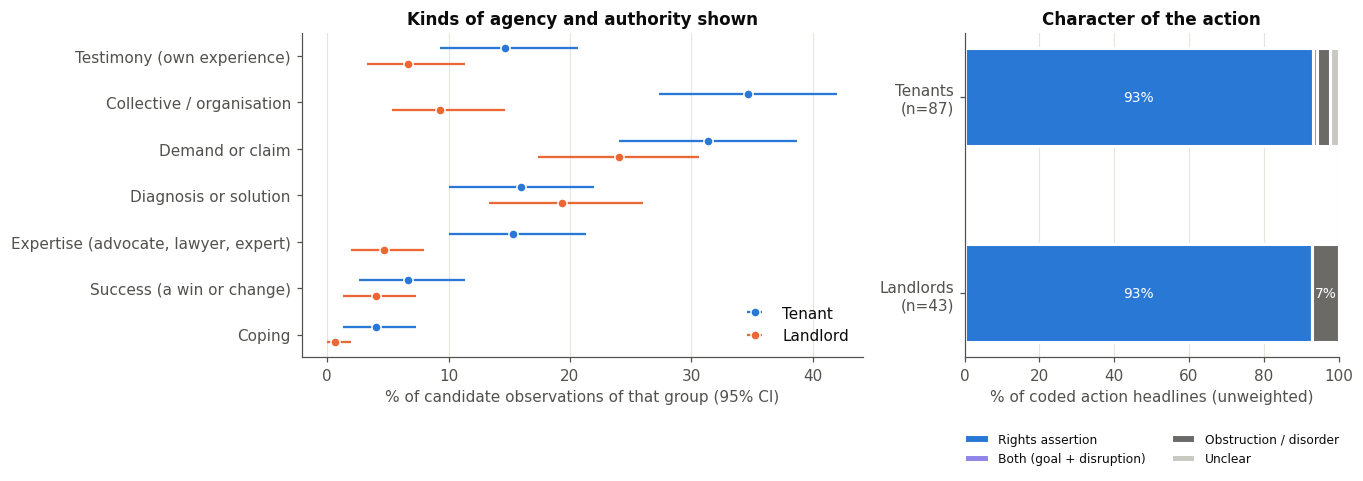

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
types = list(AG_LAB.values())
y = np.arange(len(types))[::-1]
for g, dy in [("tenant", 0.17), ("landlord", -0.17)]:
    d = q4r[q4r["group"] == g].set_index("type").loc[types]
    ax.errorbar(100 * d["rate"], y + dy, xerr=[100 * (d["rate"] - d["lo"]), 100 * (d["hi"] - d["rate"])], fmt="o", color=COLORS[g], ms=6, mec="white", lw=1.5, label=g.capitalize())
ax.set_yticks(y); ax.set_yticklabels(types); ax.set_xlabel("% of candidate observations of that group (95% CI)")
ax.set_title("Kinds of agency and authority shown"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax = axes[1]
act = Q4[Q4["has_action"]]
cats = [("A", "Rights assertion", "#2a78d6"), ("AB", "Both (goal + disruption)", "#9085e9"), ("B", "Obstruction / disorder", "#6b6a66"), ("U", "Unclear", "#c9c8c2")]
left = np.zeros(2)
for code, lab_, col in cats:
    vals = np.array([100 * (act[act["group"] == g]["action_character"].eq(code)).mean() for g in ["tenant", "landlord"]])
    ax.barh(["Tenants\n(n=%d)" % (act["group"] == "tenant").sum(), "Landlords\n(n=%d)" % (act["group"] == "landlord").sum()][::-1], vals[::-1], left=left, color=col, edgecolor="white", linewidth=2, height=0.5, label=lab_)
    for i, (v, l0) in enumerate(zip(vals[::-1], left)):
        if v >= 6:
            ax.text(l0 + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if col != "#c9c8c2" else INK)
    left += vals[::-1]
ax.set_xlim(0, 100); ax.set_xlabel("% of coded action headlines (unweighted)"); ax.set_title("Character of the action"); ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [31]:
examples_block(Q4, [
    ("Tenant success (a win or effective change)", Q4["ag_W"] & (Q4["group"] == "tenant"), 3),
    ("Collective / organisational tenant action", Q4["ag_O"] & (Q4["group"] == "tenant"), 2),
    ("Tenant action framed as obstruction or disorder", Q4["obstruct"] & (Q4["group"] == "tenant"), 2),
    ("Landlord success or organised landlord voice", (Q4["ag_W"] | Q4["ag_O"]) & (Q4["group"] == "landlord"), 2)],
    cols=["agency_types", "action_character"])

,category,group,title,media_name,publish_date,url,agency_types,action_character
0,Tenant success (a win or effective change) (n=10),tenant,Toronto tenants win fight over rental increase they argue was for redevelopment costs,cbc.ca,2025-07-30,https://www.cbc.ca/news/canada/toronto/toronto-tenants-win-fight-1.7596306?cmp=rss,W,A
1,Tenant success (a win or effective change) (n=10),tenant,"Tenant evictions challenged, overturned by new rules: Data",tj.news,2023-04-09,https://tj.news/telegraph-journal/102091635?ref=rss,W,A
2,Tenant success (a win or effective change) (n=10),tenant,Tenant strike expected to end after Toronto landlord drops bid to raise rents,nationalpost.com,2018-03-26,http://nationalpost.com/pmn/news-pmn/canada-news-pmn/tenant-strike-expected-to-end-af,OW,A
3,Collective / organisational tenant action (n=52),tenant,Toronto advocacy group pushes for maximum temperature bylaw for tenants living without air conditioning,theglobeandmail.com,2024-08-12,https://www.theglobeandmail.com/canada/article-toronto-advocacy-group-pushes-for-maxi,OD,A
4,Collective / organisational tenant action (n=52),tenant,"Kitchener's Mary Pappert recognized for advocacy work for tenants, transportation",cbc.ca,2018-01-19,http://www.cbc.ca/news/canada/kitchener-waterloo/mary-pappert-ontario-medal-for-good-,EO,-
5,Tenant action framed as obstruction or disorder (n=4),tenant,Developer won't deal with holdout Montreal tenant,winnipegfreepress.com,2023-05-31,https://www.winnipegfreepress.com/canada/2023/05/31/developer-to-let-quebec-rental-bo,-,B
6,Tenant action framed as obstruction or disorder (n=4),tenant,Renters refuse to leave Langley Township-owned home in face of Friday eviction notice,bclocalnews.com,2021-04-30,http://www.bclocalnews.com/news/renters-refuse-to-leave-langley-township-owned-home-i,-,B
7,Landlord success or organised landlord voice (n=20),landlord,Scrap 'double tax' only for local landlords: housing org,tj.news,2022-02-17,https://tj.news/greater-saint-john/101799655?ref=rss,OD,-
8,Landlord success or organised landlord voice (n=20),landlord,Sask. landlord association asks province to set up a COVID-19 rent bank,ctvnews.ca,2020-03-23,https://saskatoon.ctvnews.ca/sask-landlord-association-asks-province-to-set-up-a-covi,OD,A


In [32]:
dd = diffs4
Q4_RES = {"org": dd["O"], "test": dd["T"], "exp": dd["E"], "dem": dd["D"], "succ": dd["W"], "diag": dd["S"]}
rt = lambda t, g: q4r[(q4r["type"].str.startswith(t)) & (q4r["group"] == g)].iloc[0]
clear = [k for k, v in dd.items() if (v["lo_pp"] > 0 or v["hi_pp"] < 0) and k != "O"]
unclear = [k for k, v in dd.items() if not (v["lo_pp"] > 0 or v["hi_pp"] < 0)]
clear_txt = ", ".join(f"{AG_LAB[k].lower()} ({dd[k]['diff_pp']:+.1f} pp)" for k in clear) or "no other type"
unclear_txt = ", ".join(f"{AG_LAB[k].lower()} ({dd[k]['diff_pp']:+.1f} pp, CI {dd[k]['lo_pp']:+.1f} to {dd[k]['hi_pp']:+.1f})" for k in unclear) or "none"
obs_t, obs_l = rt("Action framed", "tenant"), rt("Action framed", "landlord")
display(Markdown(f"""**Takeaway (Q4).** Tenants are shown with **collective or organised agency far more often than landlords** ({fmt(rt(AG_LAB['O'], 'tenant'))} vs {fmt(rt(AG_LAB['O'], 'landlord'))}; difference {dd['O']['diff_pp']:+.1f} pp, CI {dd['O']['lo_pp']:+.1f} to {dd['O']['hi_pp']:+.1f}), and also more often with {clear_txt}. Not clearly different: {unclear_txt}. Wins are shown for both groups at low rates (tenants {fmt(rt(AG_LAB['W'], 'tenant'))}). When tenants act, the action is presented as **asserting rights with an explicit goal** in {100 * rt('Action asserts', 'tenant')['rate']:.0f}% of action headlines; framing as obstruction or disorder is rare ({obs_t['k']} of {obs_t['n']} tenant action headlines vs {obs_l['k']} of {obs_l['n']} landlord). Harm and effectiveness co-occur: {int(th['agency_types'].str.contains('[DOW]').sum())} of {len(th)} coded tenant observations showing harm also carry a demand, collective action or a win. This line is **closed as a disadvantage claim**, and it is a substantive **tenant-positive finding**: in this corpus tenants are routinely depicted as organised and asserting rights, not only as passive victims.

*Alternative explanations.* The candidate set is retrieval-based and includes organising stories by design; tenant organising is itself newsworthy and often press-released (advocacy groups write for headlines); and "authority" here is what the headline attributes, not what the article gives. Landlord organisations speak through associations rather than mass actions, which the "collective" code counts only as organisations."""))

**Takeaway (Q4).** Tenants are shown with **collective or organised agency far more often than landlords** (34.7% (27.3–42.0) · 52/150 vs 9.3% (5.3–14.7) · 14/150; difference +25.3 pp, CI +16.8 to +33.9), and also more often with testimony (own experience) (+8.0 pp), expertise (advocate, lawyer, expert) (+10.7 pp), coping (+3.3 pp). Not clearly different: demand or claim (+7.3 pp, CI -2.6 to +17.2), diagnosis or solution (-3.3 pp, CI -11.8 to +5.2), success (a win or change) (+2.7 pp, CI -2.6 to +7.9). Wins are shown for both groups at low rates (tenants 6.7% (2.7–11.3) · 10/150). When tenants act, the action is presented as **asserting rights with an explicit goal** in 94% of action headlines; framing as obstruction or disorder is rare (4 of 87 tenant action headlines vs 3 of 43 landlord). Harm and effectiveness co-occur: 10 of 20 coded tenant observations showing harm also carry a demand, collective action or a win. This line is **closed as a disadvantage claim**, and it is a substantive **tenant-positive finding**: in this corpus tenants are routinely depicted as organised and asserting rights, not only as passive victims.

*Alternative explanations.* The candidate set is retrieval-based and includes organising stories by design; tenant organising is itself newsworthy and often press-released (advocacy groups write for headlines); and "authority" here is what the headline attributes, not what the article gives. Landlord organisations speak through associations rather than mass actions, which the "collective" code counts only as organisations.

## 11. Shared headlines: both groups in the same sentence

A random 80 of the headlines that name **both** groups were coded for *each* group (blame, reported-speech wording, agency, action). This is a **shared-headline comparison**, not proof of editorial bias: tenant and landlord still occupy different roles inside one event, and headlines naming both groups are a selected subset. Its value is that outlet, date, topic and wording are held fixed.

In [33]:
both_fams = Hprim[Hprim["mention_group"] == "both"]
rng_sh = np.random.default_rng(SEED + 15)
sh_fams = list(both_fams.sample(80, random_state=int(rng_sh.integers(1 << 30)))["family_id_near"])
sh_cached = cr[cr["question"] == "SH"].drop_duplicates("sample_key")["family_id_near"].tolist()
print("Seeded draw reproduces the shared-headline sample:", set(sh_fams) == set(sh_cached))
sh = cr[cr["question"] == "SH"].pivot(index=["sample_key", "family_id_near", "group"], columns="field", values="value").reset_index()
sh["any_blame"] = sh["blame_status"].ne("-")
sh["own_judgment"] = sh["blame_status"].eq("O") & sh["blame_type"].isin(["E", "G"])
sh["sanction_or_allegation"] = sh["blame_type"].isin(["F", "M"]) | (sh["blame_status"].eq("A") & sh["blame_type"].isin(["E", "G"]))
sh["reported_speech"] = sh["claim_wording"].ne("-")
for k, v in {"org": "O", "demand": "D", "testimony": "T", "success": "W", "expert": "E", "diagnosis": "S"}.items():
    sh[k] = sh["agency_types"].str.contains(v)
wide_sh = sh.pivot(index="family_id_near", columns="group")
FLAGS = {"any_blame": "Any blame, judgment or sanction", "own_judgment": "Own-voice evaluative label or generalisation", "sanction_or_allegation": "Sanction, charge or described misconduct",
         "reported_speech": "Reported speech", "org": "Collective / organisation", "demand": "Demand or claim", "testimony": "Testimony", "success": "Success", "expert": "Expertise", "diagnosis": "Diagnosis or solution"}
rng = np.random.default_rng(SEED)
rows = []
for k, lab_ in FLAGS.items():
    a, b = wide_sh[k]["tenant"].astype(bool).to_numpy(), wide_sh[k]["landlord"].astype(bool).to_numpy()
    idx = rng.integers(0, len(a), size=(N_BOOT, len(a)))
    d = 100 * (a[idx].mean(1) - b[idx].mean(1))
    rows.append({"measure": lab_, "tenant": int(a.sum()), "landlord": int(b.sum()), "both": int((a & b).sum()), "tenant − landlord pp": 100 * (a.mean() - b.mean()), "lo": np.quantile(d, 0.025), "hi": np.quantile(d, 0.975)})
sh_tab = pd.DataFrame(rows).set_index("measure")
print(f"Within {len(wide_sh)} headlines naming both groups (counts of headlines where each group shows the signal; difference with a headline-level bootstrap):")
display(sh_tab.round(1))
SH_RES = sh_tab

Seeded draw reproduces the shared-headline sample: True
Within 80 headlines naming both groups (counts of headlines where each group shows the signal; difference with a headline-level bootstrap):


,tenant,landlord,both,tenant − landlord pp,lo,hi
measure,,,,,,
"Any blame, judgment or sanction",11,25,1,-17.5,-31.2,-3.8
Own-voice evaluative label or generalisation,2,0,0,2.5,0.0,6.2
"Sanction, charge or described misconduct",9,25,1,-20.0,-32.5,-6.2
Reported speech,10,12,1,-2.5,-13.8,10.0
Collective / organisation,7,0,0,8.8,2.5,15.0
Demand or claim,10,1,0,11.2,3.8,18.8
Testimony,8,7,0,1.3,-8.8,11.2
Success,4,0,0,5.0,1.2,11.2
Expertise,3,0,0,3.8,0.0,8.8


In [34]:
sh_ex = sh.join(main.drop_duplicates("family_id_near").set_index("family_id_near")[["title", "url", "publish_date", "media_name"]], on="family_id_near")
examples_block(sh_ex, [
    ("Same headline: landlord accused or sanctioned, tenants organised or demanding", (sh_ex["group"] == "landlord") & sh_ex["any_blame"] & sh_ex["family_id_near"].isin(sh_ex[(sh_ex["group"] == "tenant") & (sh_ex["org"] | sh_ex["demand"])]["family_id_near"]), 3),
    ("Same headline: tenant labelled or accused in a landlord-voiced story", (sh_ex["group"] == "tenant") & sh_ex["any_blame"], 3),
    ("Same headline: tenant win", (sh_ex["group"] == "tenant") & sh_ex["success"], 2)], cols=["blame_status", "blame_type", "agency_types"])
d_org, d_bl = sh_tab.loc["Collective / organisation"], sh_tab.loc["Any blame, judgment or sanction"]
display(Markdown(f"""**Takeaway (shared headlines).** Inside the same headline, **landlords are the party carrying blame, charges or sanctions more often** (tenant − landlord {d_bl['tenant − landlord pp']:+.1f} pp, CI {d_bl['lo']:+.1f} to {d_bl['hi']:+.1f}) and **tenants are the party carrying organisation or demands** (organisation {d_org['tenant − landlord pp']:+.1f} pp, CI {d_org['lo']:+.1f} to {d_org['hi']:+.1f}), the same pattern as in the larger samples. Own-voice evaluative labels are rare for both groups here. With only 80 headlines the intervals are wide, and tenants and landlords have different roles inside a dispute (a tenant complains, a landlord is complained about), so this is a **consistency check, not an independent test of bias**."""))

,category,group,title,media_name,publish_date,url,blame_status,blame_type,agency_types
0,"Same headline: landlord accused or sanctioned, tenants organised or demanding (n=8)",landlord,93 tenants of DTES building file complaint against landlord,globalnews.ca,2015-08-13,http://globalnews.ca/news/2165203/93-tenants-of-dtes-building-file-complaint-against-,A,M,-
1,"Same headline: landlord accused or sanctioned, tenants organised or demanding (n=8)",landlord,‘Random people would just walk into our apartment’: Tenants ask for tougher rules over landlords showing their rentals,thestar.com,2020-11-27,https://www.thestar.com/news/gta/2020/11/27/random-people-would-just-walk-into-our-ap,A,M,-
2,"Same headline: landlord accused or sanctioned, tenants organised or demanding (n=8)",landlord,Tenants accuse another landlord of bad heating during cold streak,ctvnews.ca,2018-01-05,https://montreal.ctvnews.ca/tenants-accuse-another-landlord-of-bad-heating-during-col,A,M,-
3,Same headline: tenant labelled or accused in a landlord-voiced story (n=11),tenant,Province reminds landlords: criminal tenants can be kicked out in five days,winnipegsun.com,2018-10-12,https://winnipegsun.com/news/news-news/province-reminds-landlords-criminal-tenants-ca,A,G,-
4,Same headline: tenant labelled or accused in a landlord-voiced story (n=11),tenant,B.C. creates investigative team to crack down on landlords and tenants who flout the law,thestar.com,2019-05-08,https://www.thestar.com/vancouver/2019/05/08/bc-creates-investigative-team-to-crack-d,O,M,-
5,Same headline: tenant labelled or accused in a landlord-voiced story (n=11),tenant,"‘I was almost brought to tears, how could someone do this’: Landlord’s property destroyed by rogue renters",globalnews.ca,2016-01-07,http://globalnews.ca/news/2439508/i-was-almost-brought-to-tears-how-could-someone-do-,O,E,-
6,Same headline: tenant win (n=4),tenant,Windsor landlord whose tenants paused eviction order says provincial rental board 'fails to do its job',cbc.ca,2024-11-11,https://www.cbc.ca/news/canada/windsor/landlord-tenant-board-rent-eviction-1.7380420?,-,-,W
7,Same headline: tenant win (n=4),tenant,"Victoria landlord to pay tenant $30K for noise, asbestos exposure",ctvnews.ca,2023-03-28,https://vancouverisland.ctvnews.ca/victoria-landlord-to-pay-tenant-30k-for-noise-asbe,-,-,W


**Takeaway (shared headlines).** Inside the same headline, **landlords are the party carrying blame, charges or sanctions more often** (tenant − landlord -17.5 pp, CI -31.2 to -3.8) and **tenants are the party carrying organisation or demands** (organisation +8.8 pp, CI +2.5 to +15.0), the same pattern as in the larger samples. Own-voice evaluative labels are rare for both groups here. With only 80 headlines the intervals are wide, and tenants and landlords have different roles inside a dispute (a tenant complains, a landlord is complained about), so this is a **consistency check, not an independent test of bias**.

## 12. Robustness, drivers and validation

**Key contrasts** (one or two per question, chosen before looking at subgroups) are re-estimated under the checks the brief lists, so each result is shown with how much it moves: strict residential only, excluding digest-style and pandemic items, excluding crime and incident items, dropping the three largest outlets, the two halves of the period (a transparent stratification in place of a model, given these sample sizes), and excluding renter-only wording (retrieval-wording check). The exact-title and broad-relevance sensitivity checks of earlier notebooks do not apply here because the coded samples were drawn from the primary near-family sample; the corpus-wide retrieval shares were already checked on those views in notebook 03. All other checks are **exploratory contrasts**, not a subgroup search.

robustness variants:   0%|          | 0/8 [00:00<?, ?it/s]

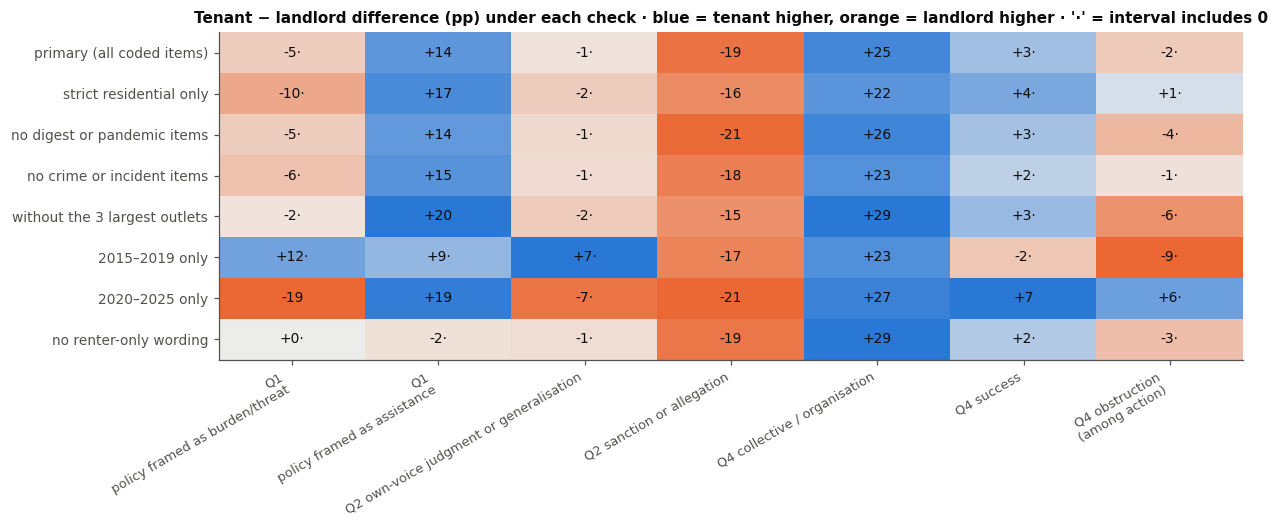

Variants (of 7 ) whose difference has the same sign as the primary estimate: {'Q1 policy framed as burden/threat': '5/7', 'Q1 policy framed as assistance': '6/7', 'Q2 own-voice judgment or generalisation': '6/7', 'Q2 sanction or allegation': '7/7', 'Q4 collective / organisation': '7/7', 'Q4 success': '6/7', 'Q4 obstruction (among action)': '5/7'}


In [35]:
top3 = main["media_name"].value_counts().head(TOP_OUTLETS).index.tolist()
VARIANTS = {
    "primary (all coded items)": lambda d: pd.Series(True, index=d.index),
    "strict residential only": lambda d: d["relevance"].eq("residential"),
    "no digest or pandemic items": lambda d: ~d["digest"] & ~d["pandemic"],
    "no crime or incident items": lambda d: ~d["crime"] & ~d["incident"],
    f"without the {TOP_OUTLETS} largest outlets": lambda d: ~d["media_name"].isin(top3),
    "2015–2019 only": lambda d: d["year"].le(2019),
    "2020–2025 only": lambda d: d["year"].ge(2020),
    "no renter-only wording": lambda d: ~(d["title"].str.contains(r"\brenters?\b", case=False) & ~d["title"].str.contains(r"\btenants?\b", case=False)),
}


def diff_from(ra, rb):
    se = np.sqrt(((ra["hi"] - ra["lo"]) / 3.92) ** 2 + ((rb["hi"] - rb["lo"]) / 3.92) ** 2)
    d = 100 * (ra["rate"] - rb["rate"])
    return d, d - 196 * se, d + 196 * se


def contrast_q1(flag, v):
    d = iv[VARIANTS[v](iv)]
    ra = wrate(d, flag, den=lambda x: x["intervention_target"] == "t", B=N_BOOT_SMALL)
    rb = wrate(d, flag, den=lambda x: x["intervention_target"] == "l", B=N_BOOT_SMALL, seed=SEED + 1)
    return diff_from(ra, rb)


def contrast_obs(df, flag, den, v):
    d = df[VARIANTS[v](df)]
    ra = wrate(d[d["group"] == "tenant"], flag, den=den, B=N_BOOT_SMALL)
    rb = wrate(d[d["group"] == "landlord"], flag, den=den, B=N_BOOT_SMALL, seed=SEED + 1)
    return diff_from(ra, rb)


CONTRASTS = {
    "Q1 policy framed as burden/threat": lambda v: contrast_q1("burden_threat", v),
    "Q1 policy framed as assistance": lambda v: contrast_q1("assistance", v),
    "Q2 own-voice judgment or generalisation": lambda v: contrast_obs(Q2, "own_judgment", None, v),
    "Q2 sanction or allegation": lambda v: contrast_obs(Q2, "sanction_or_allegation", None, v),
    "Q4 collective / organisation": lambda v: contrast_obs(Q4, "ag_O", None, v),
    "Q4 success": lambda v: contrast_obs(Q4, "ag_W", None, v),
    "Q4 obstruction (among action)": lambda v: contrast_obs(Q4, "obstruct", "has_action", v),
}
grid_rows = []
for v in tqdm(VARIANTS, desc="robustness variants"):
    for cname, fn in CONTRASTS.items():
        d, lo, hi = fn(v)
        grid_rows.append({"variant": v, "contrast": cname, "diff_pp": d, "lo": lo, "hi": hi})
rb = pd.DataFrame(grid_rows)
H = rb.pivot(index="variant", columns="contrast", values="diff_pp").reindex(list(VARIANTS))[list(CONTRASTS)]
SIGM = rb.assign(sig=lambda d: (d["lo"] > 0) | (d["hi"] < 0)).pivot(index="variant", columns="contrast", values="sig").reindex(list(VARIANTS))[list(CONTRASTS)]
fig, ax = plt.subplots(figsize=(11.5, 4.9))
scale = H.abs().max().replace(0, 1)
cmap = LinearSegmentedColormap.from_list("landlord_to_tenant", [COLORS["landlord"], NEUTRAL, COLORS["tenant"]])
ax.imshow((H / scale).values, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, f"{H.iat[i, j]:+.0f}" + ("" if SIGM.iat[i, j] else "·"), ha="center", va="center", fontsize=9, color=INK)
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels([c.replace(" (", "\n(").replace("Q1 ", "Q1 ").replace(" policy", "\npolicy") for c in H.columns], rotation=30, ha="right", fontsize=8.5)
ax.set_yticks(range(H.shape[0])); ax.set_yticklabels(H.index, fontsize=9); ax.grid(False)
ax.set_title("Tenant − landlord difference (pp) under each check · blue = tenant higher, orange = landlord higher · '·' = interval includes 0", fontsize=10)
plt.tight_layout(); plt.show()
robust_n = {c: (int((np.sign(H[c].drop(index="primary (all coded items)")) == np.sign(H.loc["primary (all coded items)", c])).sum()), len(H) - 1) for c in H.columns}
print("Variants (of", len(H) - 1, ") whose difference has the same sign as the primary estimate:", {k: f"{a}/{b}" for k, (a, b) in robust_n.items()})

In [36]:
act_rows = []
for v in VARIANTS:
    d = Q3[VARIANTS[v](Q3) & Q3["assessable"] & (Q3["mention_group"] == "tenant")]
    r = wrate(d, "actor", B=N_BOOT_SMALL)
    ri = wrate(d[d["event"] == "rent increase"], "actor", B=N_BOOT_SMALL) if (d["event"] == "rent increase").sum() >= 5 else {"k": 0, "n": int((d["event"] == "rent increase").sum()), "rate": np.nan}
    act_rows.append({"variant": v, "actor named (tenant-only harm headlines)": fmt(r), "rent-increase headlines naming an actor": f"{ri['k']}/{ri['n']}"})
display(pd.DataFrame(act_rows).set_index("variant"))
ACT_ROBUST = pd.DataFrame(act_rows)

,actor named (tenant-only harm headlines),rent-increase headlines naming an actor
variant,,
primary (all coded items),21.6% (14.6–28.4) · 25/116,1/15
strict residential only,22.8% (15.8–31.7) · 23/101,1/15
no digest or pandemic items,22.1% (15.0–30.1) · 25/113,1/15
no crime or incident items,21.8% (14.5–29.1) · 24/110,1/15
without the 3 largest outlets,28.6% (17.9–41.1) · 16/56,0/4
2015–2019 only,17.6% (7.8–29.4) · 9/51,0/6
2020–2025 only,24.6% (15.4–36.9) · 16/65,1/9
no renter-only wording,21.9% (13.5–30.2) · 21/96,1/13


**Drivers the brief asks about.** Crime and incident stories, pandemic-specific items, digest-style headlines and the retrieval wording are each excluded above; commercial relevance is addressed by the strict-residential check. Article genre cannot be established from titles and metadata, so none is inferred; "digest-style" is only a visible title pattern (newsletter, letters, "Today:"). The grid shows how far each estimate moves, and the claim ledger below uses the number of checks that keep the sign.

**Validation recap.** The frozen rules were scored on a held-out random sample (section 5). The comparison below shows how the rules do *inside the close-read candidate samples*, where they were used for retrieval: precision and recall of rule flags against my reading of the same headlines (so recall is relative to the candidates, not to the whole corpus).

,coded positives,rule positives,precision,recall
Q4 collective / organisation,66.0,94.0,0.62,0.88
Q4 demand or claim,83.0,92.0,0.63,0.70
Q4 success,16.0,44.0,0.30,0.81
Q4 testimony,32.0,23.0,0.74,0.53
Q4 expertise,30.0,30.0,0.73,0.73
Q2 any blame (rule own/attributed vs coded),92.0,100.0,0.80,0.87
Q2 hedged wording,5.0,8.0,0.62,1.00


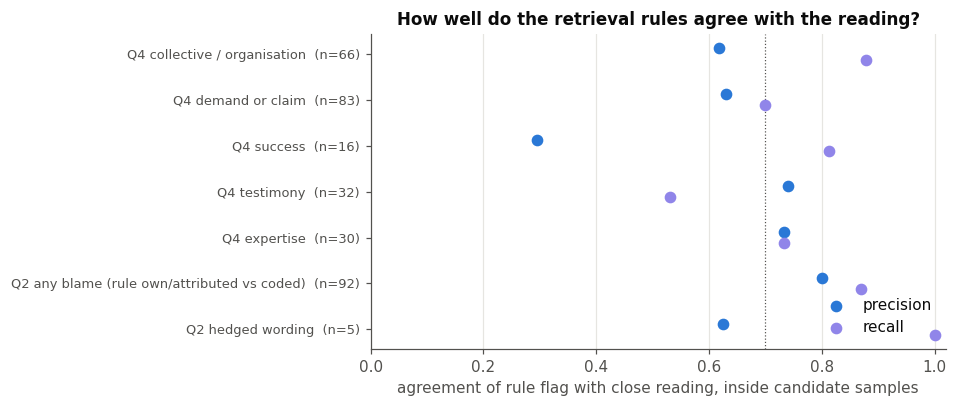

3 of 7 rule fields meet precision ≥ 0.70 and recall ≥ 0.50 with at least 10 coded positives; the rest are used for retrieval only. **No rule-based rate is quoted as a corpus estimate in this notebook.**


In [37]:
def agree(df, rule_col, code_col, group=None):
    d = df if group is None else df[df["group"] == group]
    a, b = d[rule_col].astype(bool).to_numpy(), d[code_col].astype(bool).to_numpy()
    tp, fp, fn = int((a & b).sum()), int((a & ~b).sum()), int((~a & b).sum())
    return {"coded positives": int(b.sum()), "rule positives": int(a.sum()), "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan}


rm = main.set_index(["family_id_near", "group"])
q4m = Q4.join(rm[["r_ag_collective_org", "r_ag_demand_claim", "r_ag_success", "r_ag_testimony", "r_ag_expertise", "r_moral_blame"]], on=["family_id_near", "group"])
q2m = Q2.join(rm[["r_moral_blame", "r_claim_treatment"]], on=["family_id_near", "group"])
q2m["rule_own_or_attr"] = q2m["r_moral_blame"].isin(["own", "attributed"])
q2m["rule_hedged"] = q2m["r_claim_treatment"].eq("hedged")
comp = {"Q4 collective / organisation": agree(q4m, "r_ag_collective_org", "ag_O"), "Q4 demand or claim": agree(q4m, "r_ag_demand_claim", "ag_D"), "Q4 success": agree(q4m, "r_ag_success", "ag_W"),
        "Q4 testimony": agree(q4m, "r_ag_testimony", "ag_T"), "Q4 expertise": agree(q4m, "r_ag_expertise", "ag_E"), "Q2 any blame (rule own/attributed vs coded)": agree(q2m, "rule_own_or_attr", "any_blame"),
        "Q2 hedged wording": agree(q2m, "rule_hedged", "hedged")}
comp_df = pd.DataFrame(comp).T
display(comp_df.round(2))
fig, ax = plt.subplots(figsize=(8.8, 3.8))
y = np.arange(len(comp_df))[::-1]
ax.scatter(comp_df["precision"], y + 0.12, color="#2a78d6", s=44, label="precision", zorder=3)
ax.scatter(comp_df["recall"], y - 0.12, color="#9085e9", s=44, label="recall", zorder=3)
ax.set_yticks(y); ax.set_yticklabels([f"{i}  (n={int(n)})" for i, n in zip(comp_df.index, comp_df["coded positives"])], fontsize=8.5)
ax.set_xlim(0, 1.02); ax.axvline(MIN_PRECISION, color=MUTED, lw=0.8, ls=":"); ax.set_xlabel("agreement of rule flag with close reading, inside candidate samples")
ax.set_title("How well do the retrieval rules agree with the reading?"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
n_ok = int(((comp_df["precision"] >= MIN_PRECISION) & (comp_df["recall"] >= MIN_RECALL) & (comp_df["coded positives"] >= MIN_POS_FOR_ESTIMATE)).sum())
print(f"{n_ok} of {len(comp_df)} rule fields meet precision ≥ {MIN_PRECISION:.2f} and recall ≥ {MIN_RECALL:.2f} with at least {MIN_POS_FOR_ESTIMATE} coded positives; the rest are used for retrieval only. "
      "**No rule-based rate is quoted as a corpus estimate in this notebook.**")

## 13. Claim ledger

Classification: **supported in the reviewed sample** (a countable pattern in the headlines I read, robust to the checks, but machine-assisted and not human-validated), **provisional corpus pattern** (consistent across the reviewed sample and rule-based corpus checks, but the corpus-wide measure is unvalidated), **qualitative illustration** (real headlines, too few to count), **not supported / not measurable**. No reviewed handful is promoted to a validated corpus estimate.

In [38]:
act_vals = ACT_ROBUST["actor named (tenant-only harm headlines)"].str.extract(r"^(\d+\.\d)")[0].astype(float)
act_lo, act_hi = act_vals.min(), act_vals.max()
n_a3, n_l1, n_b1 = len(a3), int(q1_n.get("landlords", 0)), int(q1_n.get("both groups", 0))
a_ = Q3_RES["actor_solo"]
ri_ = Q3_RES["ev"]["rent increase"]
ev_ = Q3_RES["ev"]["eviction"]
sd = lambda c: robust_n[c]
q2j, q2s = d_judg, d_find
ledger = [
    ("In this corpus, tenant harm is usually reported without naming who caused it, especially rent increases.",
     f"{100 * (1 - a_['rate']):.0f}% of tenant-only eviction/rent/conditions headlines name no responsible actor ({a_['k']}/{a_['n']} do); rent increases {ri_[0]}/{ri_[1]}, evictions {ev_[0]}/{ev_[1]}; actor named {100 * Q3_RES['actor_both']['rate']:.0f}% when the landlord is also in the headline.",
     f"about {100 * Q3_RES['lb']:.0f}% of all primary tenant observations (lower bound)", f"actor-named share stays between {act_lo:.0f}% and {act_hi:.0f}% across {len(VARIANTS)} checks; outlet range {100 * Q3_RES['out_min']:.0f}–{100 * Q3_RES['out_max']:.0f}%",
     f"{100 * Q3_RES['wide']['rate']:.0f}% do name a policy, market or wider condition; brevity and the grammar of rent may explain omission", f"machine-assisted close reading of {n_a3} assessable headlines; rule flag agrees with the reading in {RULE_ACTOR_AGREE:.0f}% of tenant-only cases", "tenant-only headlines about eviction, rent increases and conditions; says nothing about articles",
     "Provisional corpus pattern"),
    ("When an individual tenant's reason for not paying rent is given, it is far more often refusal or exploitation than inability.",
     f"{NP_RES['n_ref']} refusal/exploitation vs {NP_RES['n_inab']} inability among {NP_RES['n_indiv']} individual-motive headlines; {NP_RES['n_ref_own']} of the {NP_RES['n_ref']} in the headline's own voice; {NP_RES['n_coll']} of {NP_RES['n_tn']} non-payment headlines are rent strikes",
     f"{NP_RES['n_tn']} tenant non-payment headlines out of the primary sample (census)", "census of retrieved headlines; not resampled; counts too small for subgroup checks",
     "individual-motive stories are enforcement and fraud reports; hardship arrears appear as aggregate figures without a motive; retrieval keyed on non-payment words", "single-reader census (machine-assisted)", "headlines retrieved by non-payment wording; needs article-level follow-up", "Supported in the reviewed sample"),
    ("Landlord-side burden narratives about regulation exist, are mostly attributed to landlord-side speakers, and sometimes come with personal hardship detail.",
     f"{Q1_RES['l_burden'] * 100:.0f}% of landlord-targeted policy headlines are framed as burden; {Q1_RES['n_att']} of {Q1_RES['n_b']} burden headlines attribute the claim; hardship detail in {Q1_RES['hum_b']} of {Q1_RES['n_b']} vs {Q1_RES['hum_n']} of {Q1_RES['nonb_n']} other landlord-targeted headlines",
     f"{Q1_RES['l_burden'] * 100:.0f}% of landlord-targeted policy headlines", f"burden share difference keeps its sign in {sd('Q1 policy framed as burden/threat')[0]} of {sd('Q1 policy framed as burden/threat')[1]} checks", f"tenant-targeted policy is framed as a burden on tenants in {Q1_RES['t_burden'] * 100:.0f}% of headlines; {Q1_RES['n_b'] - Q1_RES['n_att']} of {Q1_RES['n_b']} burden claims are in the headline's own voice", f"machine-assisted close reading of {n_l1} landlord-targeted and {n_b1} both-group intervention headlines", "counts of hardship co-occurrence are single digits; lobbying intent cannot be assessed", "Qualitative illustration"),
    ("Tenants are shown as organised, demanding and asserting rights at least as much as landlords; tenant action is rarely framed as obstruction.",
     f"collective/organisation {Q4_RES['org']['diff_pp']:+.1f} pp (CI {Q4_RES['org']['lo_pp']:+.1f} to {Q4_RES['org']['hi_pp']:+.1f}); demands {Q4_RES['dem']['diff_pp']:+.1f} pp; obstruction in {obs_t['k']}/{obs_t['n']} tenant action headlines",
     f"organisation in {100 * rt(AG_LAB['O'], 'tenant')['rate']:.0f}% of tenant candidate observations vs {100 * rt(AG_LAB['O'], 'landlord')['rate']:.0f}% of landlord ones", f"organisation difference keeps its sign in {sd('Q4 collective / organisation')[0]} of {sd('Q4 collective / organisation')[1]} checks", "retrieval includes organising stories by design; press-release effects; landlords speak through associations", f"machine-assisted close reading of {len(Q4)} observations", "headline attribution only", "Provisional corpus pattern"),
    ("Tenant policy is framed as rights/protection more than as assistance.",
     f"tenant-targeted: protective {Q1_RES['t_prot'] * 100:.0f}% vs assistance {Q1_RES['t_assist'] * 100:.0f}%; landlord-targeted accountability {Q1_RES['l_acc'] * 100:.0f}%",
     f"{int(q1_n.get('tenants', 0))} tenant-targeted and {n_l1} landlord-targeted intervention headlines", f"assistance difference keeps its sign in {sd('Q1 policy framed as assistance')[0]} of {sd('Q1 policy framed as assistance')[1]} checks", f"protection can itself be paternalistic (literature); this code does not test that. Excluding renter-only wording moves the assistance difference to {H.loc['no renter-only wording', 'Q1 policy framed as assistance']:+.0f} pp (from {H.loc['primary (all coded items)', 'Q1 policy framed as assistance']:+.0f}), so assistance framing depends on the word renters", "machine-assisted close reading", "policy agenda fixes the target; wide intervals", "Provisional corpus pattern"),
    ("Headline judgments of tenants are harsher than of landlords.",
     f"own-voice judgment {q2j['diff_pp']:+.1f} pp (CI {q2j['lo_pp']:+.1f} to {q2j['hi_pp']:+.1f}); landlord sanctions and allegations are higher (finding {q2s['diff_pp']:+.1f} pp)", "—", f"judgment difference keeps its sign in {sd('Q2 own-voice judgment or generalisation')[0]} of {sd('Q2 own-voice judgment or generalisation')[1]} checks", "tenant labels are specific ('thug tenants'); landlord labels are class-level", "machine-assisted close reading", "—", "Not supported"),
    ("Tenants' claims are reported with more scepticism than landlords'.",
     f"hedged wording in {Q2_RES['n_h_t']} tenant vs {Q2_RES['n_h_l']} landlord headlines with reported speech", "too rare", "—", "—", "—", "—", "Not measurable (too few cases)"),
]
led = pd.DataFrame(ledger, columns=["Claim (proposed wording)", "Supporting numbers", "Extent", "Robustness", "Contradictory evidence / alternatives", "Validation status", "Narrowest defensible scope", "Classification"])
md_rows = ["| " + " | ".join(led.columns) + " |", "|" + "---|" * len(led.columns)]
for r in led.itertuples(index=False):
    md_rows.append("| " + " | ".join(str(x).replace("|", "/").replace("\n", " ") for x in r) + " |")
display(Markdown("\n".join(md_rows)))
print("Human-review file:", "still blank, so none of the above is human-validated." if n_human == 0 else "has labels; see section 4.")

| Claim (proposed wording) | Supporting numbers | Extent | Robustness | Contradictory evidence / alternatives | Validation status | Narrowest defensible scope | Classification |
|---|---|---|---|---|---|---|---|
| In this corpus, tenant harm is usually reported without naming who caused it, especially rent increases. | 78% of tenant-only eviction/rent/conditions headlines name no responsible actor (25/116 do); rent increases 1/15, evictions 18/74; actor named 95% when the landlord is also in the headline. | about 16% of all primary tenant observations (lower bound) | actor-named share stays between 18% and 29% across 8 checks; outlet range 6–18% | 43% do name a policy, market or wider condition; brevity and the grammar of rent may explain omission | machine-assisted close reading of 179 assessable headlines; rule flag agrees with the reading in 80% of tenant-only cases | tenant-only headlines about eviction, rent increases and conditions; says nothing about articles | Provisional corpus pattern |
| When an individual tenant's reason for not paying rent is given, it is far more often refusal or exploitation than inability. | 16 refusal/exploitation vs 4 inability among 23 individual-motive headlines; 10 of the 16 in the headline's own voice; 41 of 94 non-payment headlines are rent strikes | 94 tenant non-payment headlines out of the primary sample (census) | census of retrieved headlines; not resampled; counts too small for subgroup checks | individual-motive stories are enforcement and fraud reports; hardship arrears appear as aggregate figures without a motive; retrieval keyed on non-payment words | single-reader census (machine-assisted) | headlines retrieved by non-payment wording; needs article-level follow-up | Supported in the reviewed sample |
| Landlord-side burden narratives about regulation exist, are mostly attributed to landlord-side speakers, and sometimes come with personal hardship detail. | 18% of landlord-targeted policy headlines are framed as burden; 18 of 23 burden headlines attribute the claim; hardship detail in 5 of 23 vs 0 of 75 other landlord-targeted headlines | 18% of landlord-targeted policy headlines | burden share difference keeps its sign in 5 of 7 checks | tenant-targeted policy is framed as a burden on tenants in 14% of headlines; 5 of 23 burden claims are in the headline's own voice | machine-assisted close reading of 92 landlord-targeted and 37 both-group intervention headlines | counts of hardship co-occurrence are single digits; lobbying intent cannot be assessed | Qualitative illustration |
| Tenants are shown as organised, demanding and asserting rights at least as much as landlords; tenant action is rarely framed as obstruction. | collective/organisation +25.3 pp (CI +16.8 to +33.9); demands +7.3 pp; obstruction in 4/87 tenant action headlines | organisation in 35% of tenant candidate observations vs 9% of landlord ones | organisation difference keeps its sign in 7 of 7 checks | retrieval includes organising stories by design; press-release effects; landlords speak through associations | machine-assisted close reading of 300 observations | headline attribution only | Provisional corpus pattern |
| Tenant policy is framed as rights/protection more than as assistance. | tenant-targeted: protective 55% vs assistance 23%; landlord-targeted accountability 46% | 73 tenant-targeted and 92 landlord-targeted intervention headlines | assistance difference keeps its sign in 6 of 7 checks | protection can itself be paternalistic (literature); this code does not test that. Excluding renter-only wording moves the assistance difference to -2 pp (from +14), so assistance framing depends on the word renters | machine-assisted close reading | policy agenda fixes the target; wide intervals | Provisional corpus pattern |
| Headline judgments of tenants are harsher than of landlords. | own-voice judgment -0.7 pp (CI -6.8 to +5.5); landlord sanctions and allegations are higher (finding -10.7 pp) | — | judgment difference keeps its sign in 6 of 7 checks | tenant labels are specific ('thug tenants'); landlord labels are class-level | machine-assisted close reading | — | Not supported |
| Tenants' claims are reported with more scepticism than landlords'. | hedged wording in 4 tenant vs 1 landlord headlines with reported speech | too rare | — | — | — | — | Not measurable (too few cases) |

Human-review file: still blank, so none of the above is human-validated.


## 14. Story outline, rejected lines, and what remains

In [39]:
stories = [
    ("Rents go up. Nobody does it.",
     f"In this corpus a tenant-only headline about a rent increase, an eviction or a housing problem names who did it only about {100 * a_['rate']:.0f}% of the time ({ri_[0]} of {ri_[1]} rent-increase headlines). When the landlord is in the headline, the actor is named.",
     ["Bars: share of tenant-only harm headlines naming an actor, by event type (figure in section 9)", "Paired headline pairs: the same rent increase with and without a named landlord", "Outlet dot plot of actor-named share (rule-based)", "Annotated list of 8 headlines (section 9 examples)"],
     "Narrow to 'in this corpus, headline wording'; do not say outlets hide landlords; pursue the article-level check first."),
    ("Not paying rent: strike, scam or struggle?",
     f"When headlines give a reason for an individual tenant not paying, they describe refusal or exploitation ({NP_RES['n_ref']}) about {NP_RES['n_ref'] / max(NP_RES['n_inab'], 1):.0f} times as often as inability ({NP_RES['n_inab']}), while the largest group of non-payment headlines are rent strikes ({NP_RES['n_coll']}).",
     ["Stacked bar of motives by voice (section 8)", "Timeline of rent-strike headlines", "Quote cards for the refusal and inability headlines", "Side note on hardship arrears appearing only as statistics"],
     "Single-reader census; verify a sample of articles before publishing; do not generalise to 'tenants are painted as deadbeats'."),
]
display(Markdown("**Story claims the evidence can carry (two, not three):**\n\n" + "\n\n".join(
    f"**{i + 1}. {t}** — {c}  \n*Visuals:* " + "; ".join(v) + f".  \n*Scope:* {s}" for i, (t, c, v, s) in enumerate(stories))))
display(Markdown(f"""**A third angle was considered and kept narrower.** Landlord-side burden narratives with hardship detail ({Q1_RES['hum_b']} of {Q1_RES['n_b']} burden headlines) match the commentary that motivated the question, but at single-digit counts and with the claims attributed to landlord-side speakers; it is offered as a qualitative illustration, not a story claim.

**Lines of inquiry closed or rejected.** (1) *Tenants judged more harshly in the headline's own voice*: own-voice judgments are similar for both groups and sanctions run against landlords. (2) *Tenants framed as disorderly or obstructive*: framing as obstruction is rare ({obs_t['k']} of {obs_t['n']} tenant action headlines). (3) *Tenants' claims discredited through hedged wording*: too few cases to measure. (4) *Tenant protections framed mainly as charity*: they are framed more as rights or protection than as assistance. (5) *Individualisation* (notebook 03's individual-case gap): largely a singular/plural wording artifact, not pursued. No smaller subgroup was searched after a null result.

**Remaining validation needs.** (a) Human labels on the machine-assisted samples, starting with `actor_named`, the non-payment census and `collective_org`; the 120-row human-review file from notebook 02 is still {'blank' if n_human == 0 else 'partly filled'}. (b) A larger random validation sample if any rule-based rate is to be quoted at corpus level. (c) Span-level evidence for the close-read labels (only pilot and validation labels carry spans).

**Claims that need article-level follow-up.** Whether agentless tenant-harm headlines correspond to agentless articles; whether non-payment motives in headlines match the article; whether landlord burden claims in headlines are part of organised advocacy; and any statement about journalists' intent or audience effects, which headlines cannot establish.

**Limits.** English-language indexed headlines retrieved by role keywords; uneven indexing; machine-assisted coding by a single reader; conditional rates among rule-retrieved candidates; no population or exposure comparisons. Intervals describe corpus and resampling uncertainty, not inference to all media."""))

**Story claims the evidence can carry (two, not three):**

**1. Rents go up. Nobody does it.** — In this corpus a tenant-only headline about a rent increase, an eviction or a housing problem names who did it only about 22% of the time (1 of 15 rent-increase headlines). When the landlord is in the headline, the actor is named.  
*Visuals:* Bars: share of tenant-only harm headlines naming an actor, by event type (figure in section 9); Paired headline pairs: the same rent increase with and without a named landlord; Outlet dot plot of actor-named share (rule-based); Annotated list of 8 headlines (section 9 examples).  
*Scope:* Narrow to 'in this corpus, headline wording'; do not say outlets hide landlords; pursue the article-level check first.

**2. Not paying rent: strike, scam or struggle?** — When headlines give a reason for an individual tenant not paying, they describe refusal or exploitation (16) about 4 times as often as inability (4), while the largest group of non-payment headlines are rent strikes (41).  
*Visuals:* Stacked bar of motives by voice (section 8); Timeline of rent-strike headlines; Quote cards for the refusal and inability headlines; Side note on hardship arrears appearing only as statistics.  
*Scope:* Single-reader census; verify a sample of articles before publishing; do not generalise to 'tenants are painted as deadbeats'.

**A third angle was considered and kept narrower.** Landlord-side burden narratives with hardship detail (5 of 23 burden headlines) match the commentary that motivated the question, but at single-digit counts and with the claims attributed to landlord-side speakers; it is offered as a qualitative illustration, not a story claim.

**Lines of inquiry closed or rejected.** (1) *Tenants judged more harshly in the headline's own voice*: own-voice judgments are similar for both groups and sanctions run against landlords. (2) *Tenants framed as disorderly or obstructive*: framing as obstruction is rare (4 of 87 tenant action headlines). (3) *Tenants' claims discredited through hedged wording*: too few cases to measure. (4) *Tenant protections framed mainly as charity*: they are framed more as rights or protection than as assistance. (5) *Individualisation* (notebook 03's individual-case gap): largely a singular/plural wording artifact, not pursued. No smaller subgroup was searched after a null result.

**Remaining validation needs.** (a) Human labels on the machine-assisted samples, starting with `actor_named`, the non-payment census and `collective_org`; the 120-row human-review file from notebook 02 is still blank. (b) A larger random validation sample if any rule-based rate is to be quoted at corpus level. (c) Span-level evidence for the close-read labels (only pilot and validation labels carry spans).

**Claims that need article-level follow-up.** Whether agentless tenant-harm headlines correspond to agentless articles; whether non-payment motives in headlines match the article; whether landlord burden claims in headlines are part of organised advocacy; and any statement about journalists' intent or audience effects, which headlines cannot establish.

**Limits.** English-language indexed headlines retrieved by role keywords; uneven indexing; machine-assisted coding by a single reader; conditional rates among rule-retrieved candidates; no population or exposure comparisons. Intervals describe corpus and resampling uncertainty, not inference to all media.

In [40]:
check = {"primary families": main["family_id_near"].nunique(), "coded close-reading items": int(cr["sample_key"].nunique()), "human labels in review file": n_human}
print(check)
print("Cache files written by this notebook: none (machine-assisted labels are read from review/machine_assisted_coding.csv and review/closeread_coding.csv).")

{'primary families': 5611, 'coded close-reading items': 1281, 'human labels in review file': 0}
Cache files written by this notebook: none (machine-assisted labels are read from review/machine_assisted_coding.csv and review/closeread_coding.csv).
